# Phase 3 – Rhetorical Role Prediction: full experiment notebook

Hierarchical, document-aware RR classifier on top of your **Phase-1 encoder-decoder** (encoder only), with swappable
adaptation methods so all experiments share one pipeline and one metric.

**Architecture.** sentence → Phase-1 encoder → masked mean-pool → [+ relative-position features + domain embedding]
→ 2-layer BiGRU over the sentences of the document → 13-way label per sentence.
Training uses windows of consecutive sentences (global position features preserved); inference runs the BiGRU over the whole document.

**Adaptation methods (`cfg["method"]`)**

| key | method | trainable |
|---|---|---|
| `frozen` | linear-probe style: Phase-1 frozen, head only (diagnostic baseline) | head |
| `full` | full fine-tuning | everything |
| `partial` | top-k encoder layers | k layers + head |
| `lora` / `rslora` | LoRA / rank-stabilised LoRA (`α/√r`) | adapters + head |
| `lorma` | LoRMA+ (multiplicative, additive-inflation variant) | adapters + head |
| `ia3` | IA³ (learned scaling of K, V, FFN activations) | scales + head |
| `prompt` | prompt tuning (learned soft tokens prepended to each sentence) | prompt + head |
| KD | `run_rr(..., teacher=..., n_layers=k)` – truncated-encoder student distilled from a trained teacher | student |

**Read before running**
* I could not run this on a GPU here (no torch in my sandbox). Syntax and name checks were done, nothing else — expect to debug a typo or shape issue on first run, and send me the traceback.
* **LoRMA+** is implemented from my reading of the paper (Bihany et al., ACL Findings 2025): `W' = (I + (α/r)·BA)·W₀`, computed as `h + s·B(A h)` with `h = W₀x` so no d×d matrix is built; `B` is zero-initialised so training starts at the Phase-1 function. Check it against the paper and the authors' repo (github.com/Exploration-Lab/LoRMA); LoRMAπ is not implemented.
* The Phase-1 model uses bias-free linears, so **BitFit has nothing to tune** here; AdaLoRA and prefix-tuning are left out (more invasive). Swap in others if you need them.
* Hyper-parameters in `BASE_CFG` are starting points, not tuned values.
* **Other Phase-1 architectures:** the code needs a backbone exposing `.embed(ids)`, `.encoder(emb, mask)` and `.d_model`. See Section 5 to register more.

## 1. Config, data, cleaning, metrics, logger, submission utilities

In [ ]:
import os, sys, re, json, random, unicodedata, zipfile, time, math
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix

SEED = 42
random.seed(SEED); np.random.seed(SEED)

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    OUTPUT_DIR = "/content/drive/MyDrive/Phase3_Rhetorical_Role_prediction"
else:
    OUTPUT_DIR = "./phase3_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)
DATA_DIR = "./phase3_rr_data"
os.makedirs(DATA_DIR, exist_ok=True)

# NEVER paste a token in the notebook. Use Colab secrets (key name HF_TOKEN) or an env var.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None and IN_COLAB:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        pass
print("Output dir:", OUTPUT_DIR, "| HF token set:", HF_TOKEN is not None)

Mounted at /content/drive
Output dir: /content/drive/MyDrive/Phase3_Rhetorical_Role_prediction | HF token set: True


In [ ]:
import torch, torch.nn as nn, torch.nn.functional as F, copy, gc, heapq
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
if DEVICE.type == "cuda":
    torch.cuda.manual_seed_all(SEED); print("GPU:", torch.cuda.get_device_name(0))
torch.manual_seed(SEED)

# ---- EDIT: Phase-1 artefacts (encoder-decoder run) ----
PHASE1_WORK_DIR = "/content/drive/MyDrive/Phase1_Pretraining/phase1_encoder_decoder"
CHECKPOINT_PATH = os.path.join(PHASE1_WORK_DIR, "checkpoints", "encoder_decoder_best.pt")
TOKENIZER_PATH  = os.path.join(PHASE1_WORK_DIR, "final_bpe_en.json")

GPU: Tesla T4


In [ ]:
from huggingface_hub import hf_hub_download

REPO_ID = "Exploration-Lab/CS-781-Capstone"
PHASE3_FILES = {
    "CL_train": "Phase_3_RR/Train/CL_train.json", "CL_dev": "Phase_3_RR/Train/CL_dev.json",
    "IT_train": "Phase_3_RR/Train/IT_train.json", "IT_dev": "Phase_3_RR/Train/IT_dev.json",
    "label_vocab": "Phase_3_RR/Train/label_vocab.json",
    "CL_test": "Phase_3_RR/Test/CL_test.json",   "IT_test": "Phase_3_RR/Test/IT_test.json",
}
raw_data = {}
for key, fn in PHASE3_FILES.items():
    p = hf_hub_download(repo_id=REPO_ID, filename=fn, repo_type="dataset", token=HF_TOKEN, local_dir=DATA_DIR)
    with open(p, encoding="utf-8") as f:
        raw_data[key] = json.load(f)
    print(key, "->", p)

CL_train.json:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

CL_train -> /content/phase3_rr_data/Phase_3_RR/Train/CL_train.json


CL_dev.json:   0%|          | 0.00/336k [00:00<?, ?B/s]

CL_dev -> /content/phase3_rr_data/Phase_3_RR/Train/CL_dev.json


IT_train.json:   0%|          | 0.00/1.51M [00:00<?, ?B/s]

IT_train -> /content/phase3_rr_data/Phase_3_RR/Train/IT_train.json


... (4 outputs left out)

CL_test.json:   0%|          | 0.00/281k [00:00<?, ?B/s]

CL_test -> /content/phase3_rr_data/Phase_3_RR/Test/CL_test.json


IT_test.json:   0%|          | 0.00/194k [00:00<?, ?B/s]

IT_test -> /content/phase3_rr_data/Phase_3_RR/Test/IT_test.json


In [ ]:
def normalize_sentence(x):
    s = unicodedata.normalize("NFKC", "" if x is None else str(x))
    return re.sub(r"\s+", " ", s.replace("\u00a0", " ")).strip()

def load_labels(raw_vocab):
    if isinstance(raw_vocab, list): labels = raw_vocab
    elif isinstance(raw_vocab, dict) and all(isinstance(v, int) for v in raw_vocab.values()):
        labels = [k for k, _ in sorted(raw_vocab.items(), key=lambda kv: kv[1])]
    elif isinstance(raw_vocab, dict) and "labels" in raw_vocab: labels = raw_vocab["labels"]
    else: labels = list(raw_vocab.keys())
    labels = [str(l) for l in labels]
    assert len(labels) == len(set(labels))
    return labels

def as_rows(raw):
    if isinstance(raw, dict):
        raw = raw["data"] if "data" in raw else [{**v, "id": k} if isinstance(v, dict) else {"id": k, "text": v} for k, v in raw.items()]
    return raw

def clean_split(raw, name, labeled, label_set):
    out, rep = [], Counter()
    for item in as_rows(raw):
        doc_id = str(item.get("id", item.get("doc_id")))
        sents, labs = item["text"], item.get("labels")
        if labeled:
            assert labs is not None and len(labs) == len(sents), f"{name}/{doc_id}: sentence/label mismatch"
        ns, nl = [], []
        for i, s in enumerate(sents):
            t = normalize_sentence(s)
            if not t:
                if labeled:
                    rep["empty_dropped"] += 1; continue        # drop sentence AND its label
                t = "."; rep["empty_placeholder_test"] += 1     # keep position for test
            ns.append(t)
            if labeled:
                assert labs[i] in label_set, f"{name}/{doc_id}: unknown label {labs[i]!r}"
                nl.append(labs[i])
        if not ns: rep["empty_docs_dropped"] += 1; continue
        out.append({"id": doc_id, "text": ns, **({"labels": nl} if labeled else {})})
        rep["docs"] += 1; rep["sentences"] += len(ns)
    return out, dict(rep)

LABELS = load_labels(raw_data["label_vocab"]); LABEL_SET = set(LABELS)
label_to_id = {l: i for i, l in enumerate(LABELS)}; id_to_label = {i: l for l, i in label_to_id.items()}
cleaned, reports = {}, {}
for k in ["CL_train", "CL_dev", "IT_train", "IT_dev"]:
    cleaned[k], reports[k] = clean_split(raw_data[k], k, True, LABEL_SET)
for k in ["CL_test", "IT_test"]:
    cleaned[k], reports[k] = clean_split(raw_data[k], k, False, LABEL_SET)
print(json.dumps(reports, indent=1))
# Sanity: test docs must keep their original sentence counts
for k in ["CL_test", "IT_test"]:
    orig = {str(r.get("id")): len(r["text"]) for r in as_rows(raw_data[k])}
    assert all(orig[d["id"]] == len(d["text"]) for d in cleaned[k]), f"{k}: sentence count changed!"
print("Test sentence counts preserved.")

{
 "CL_train": {
  "docs": 40,
  "sentences": 10593
 },
 "CL_dev": {
  "docs": 5,
  "sentences": 1396
 },
 "IT_train": {
  "docs": 40,
  "sentences": 6252
 },
 "IT_dev": {
  "docs": 5,
  "sentences": 746
 },
 "CL_test": {
  "docs": 5,
  "sentences": 1339
 },
 "IT_test": {
  "docs": 5,
  "sentences": 858
 }
}
Test sentence counts preserved.


                        CL_train  CL_dev  IT_train  IT_dev
Fact                        2979     249      1119     195
Issue                         17       3        90      12
ArgumentPetitioner           976     344       637      56
ArgumentRespondent           996     236       352      36
Statute                      367      58       732      62
Dissent                      284       0         0       0
PrecedentReliedUpon         1305     142       640     112
PrecedentNotReliedUpon       209       0       360      50
PrecedentOverruled             0       0         3       0
RulingByLowerCourt           438      56       436      46
RatioOfTheDecision          2856     288      1445     115
RulingByPresentCourt         113      18       194      31
None                          53       2       244      31
CL dev classes with zero support: ['Dissent', 'PrecedentNotReliedUpon', 'PrecedentOverruled']
IT dev classes with zero support: ['Dissent', 'PrecedentOverruled']


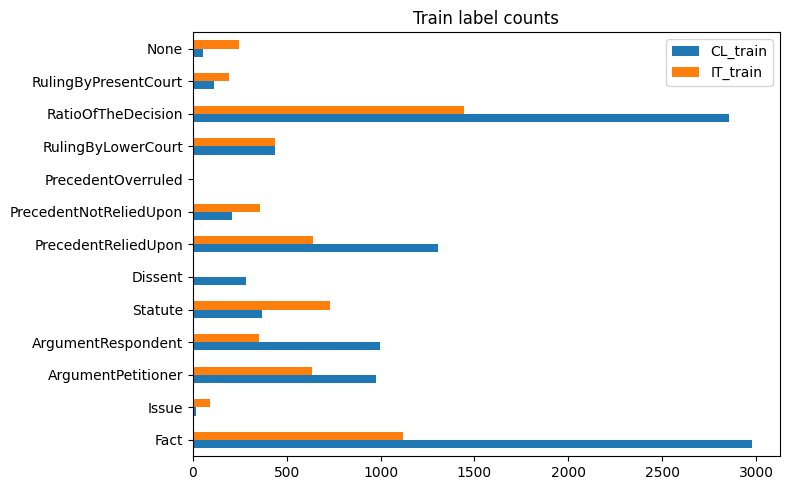


CL doc lengths: {'min': 19.0, '50%': 120.5, 'max': 1816.0}
IT doc lengths: {'min': 25.0, '50%': 126.5, 'max': 442.0}

CL relative position by role
                             n  mean_pos  std_pos
Fact                    2979.0     0.294    0.262
Issue                     17.0     0.348    0.202
ArgumentPetitioner       976.0     0.326    0.187
ArgumentRespondent       996.0     0.388    0.161
Statute                  367.0     0.440    0.179
Dissent                  284.0     0.872    0.082
PrecedentReliedUpon     1305.0     0.706    0.211
PrecedentNotReliedUpon   209.0     0.317    0.228
PrecedentOverruled         NaN       NaN      NaN
RulingByLowerCourt       438.0     0.487    0.294
RatioOfTheDecision      2856.0     0.682    0.194
RulingByPresentCourt     113.0     0.966    0.064
None                      53.0     0.765    0.228

IT relative position by role
                             n  mean_pos  std_pos
Fact                    1119.0     0.264    0.258
Issue                 

In [ ]:
def label_dist(domain):
    rows = {}
    for split in ["train", "dev"]:
        c = Counter(l for d in cleaned[f"{domain}_{split}"] for l in d["labels"])
        rows[f"{domain}_{split}"] = [c.get(l, 0) for l in LABELS]
    return pd.DataFrame(rows, index=LABELS)

dist = pd.concat([label_dist("CL"), label_dist("IT")], axis=1)
display(dist) if "display" in dir() else print(dist)

# Classes with zero support in a dev split: they make a naive 13-class macro-F1 impossible to maximise
for dom in ["CL", "IT"]:
    zero = [l for l in LABELS if dist.loc[l, f"{dom}_dev"] == 0]
    print(f"{dom} dev classes with zero support: {zero}")

ax = dist[["CL_train", "IT_train"]].plot.barh(figsize=(8, 5), title="Train label counts")
plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, "label_distribution.png"), dpi=150); plt.show()

# Document lengths and where each role tends to occur (relative position) – evidence for/against context models
def rel_pos_table(docs):
    pos = defaultdict(list)
    for d in docs:
        n = len(d["text"])
        for i, l in enumerate(d["labels"]): pos[l].append(i / max(n - 1, 1))
    return pd.DataFrame({l: {"n": len(v), "mean_pos": np.mean(v), "std_pos": np.std(v)} for l, v in pos.items()}).T.reindex(LABELS)
print("\nCL doc lengths:", pd.Series([len(d["text"]) for d in cleaned["CL_train"]]).describe()[["min", "50%", "max"]].to_dict())
print("IT doc lengths:", pd.Series([len(d["text"]) for d in cleaned["IT_train"]]).describe()[["min", "50%", "max"]].to_dict())
print("\nCL relative position by role"); print(rel_pos_table(cleaned["CL_train"]).round(3))
print("\nIT relative position by role"); print(rel_pos_table(cleaned["IT_train"]).round(3))

# How often does a sentence share its label with the previous one? (label "stickiness" = how much context can help)
for dom in ["CL", "IT"]:
    same = tot = 0
    for d in cleaned[f"{dom}_train"]:
        for a, b in zip(d["labels"][:-1], d["labels"][1:]): same += (a == b); tot += 1
    print(f"{dom}: P(label_t == label_t-1) = {same/tot:.3f}")

In [ ]:
def flatten(docs, pred_map):
    yt, yp = [], []
    for d in docs:
        p = pred_map[d["id"]]
        assert len(p) == len(d["labels"]), f"{d['id']}: {len(p)} preds vs {len(d['labels'])} gold"
        yt += d["labels"]; yp += list(p)
    return yt, yp

def rr_scores(y_true, y_pred):
    variants = {"all13": LABELS, "union": sorted(set(y_true) | set(y_pred)), "support": sorted(set(y_true))}
    out = {}
    for name, labs in variants.items():
        p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=labs, average="macro", zero_division=0)
        out[name] = {"P": float(p), "R": float(r), "F1": float(f)}
    out["accuracy"] = float(np.mean(np.array(y_true) == np.array(y_pred)))
    return out

def per_class_report(y_true, y_pred):
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=LABELS, zero_division=0)
    n_pred = Counter(y_pred)
    return pd.DataFrame({"precision": p, "recall": r, "f1": f, "support": s,
                         "n_predicted": [n_pred.get(l, 0) for l in LABELS]}, index=LABELS).round(3)

def plot_confusion(y_true, y_pred, title, path=None):
    cm = confusion_matrix(y_true, y_pred, labels=LABELS)
    cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(8, 7)); im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(LABELS))); ax.set_xticklabels(LABELS, rotation=90, fontsize=7)
    ax.set_yticks(range(len(LABELS))); ax.set_yticklabels(LABELS, fontsize=7)
    ax.set_xlabel("predicted"); ax.set_ylabel("gold"); ax.set_title(title); fig.colorbar(im)
    plt.tight_layout()
    if path: plt.savefig(path, dpi=150)
    plt.show()

def evaluate_split(docs, pred_map):
    yt, yp = flatten(docs, pred_map)
    return rr_scores(yt, yp), yt, yp

In [ ]:
REGISTRY_PATH = os.path.join(OUTPUT_DIR, "experiment_registry.csv")
registry = pd.read_csv(REGISTRY_PATH).to_dict("records") if os.path.exists(REGISTRY_PATH) else []

def log_experiment(name, technique, phase1_model, trainable_params, total_params, scores_by_domain,
                   train_seconds=None, notes="", submitted_to_codabench=False):
    row = {"name": name, "technique": technique, "phase1_model": phase1_model,
           "trainable_params": trainable_params, "total_params": total_params, "train_seconds": train_seconds,
           "notes": notes, "submitted": submitted_to_codabench, "time": time.strftime("%Y-%m-%d %H:%M")}
    for dom, sc in scores_by_domain.items():
        for variant in ["all13", "union", "support"]:
            row[f"{dom}_F1_{variant}"] = round(sc[variant]["F1"], 4)
    f1s = [sc["union"]["F1"] for sc in scores_by_domain.values()]
    row["mean_F1_union"] = round(float(np.mean(f1s)), 4)
    registry.append(row)
    pd.DataFrame(registry).to_csv(REGISTRY_PATH, index=False)
    return row

In [ ]:
def build_submission(cl_pred, it_pred):
    ids_overlap = set(cl_pred) & set(it_pred)
    if ids_overlap:
        raise ValueError(f"CL/IT document-ID collision ({list(ids_overlap)[:3]}...). Ask the TAs how to merge before submitting.")
    return {**cl_pred, **it_pred}

def validate_submission(sub):
    expected = {d["id"]: len(d["text"]) for k in ["CL_test", "IT_test"] for d in cleaned[k]}
    missing, extra = set(expected) - set(sub), set(sub) - set(expected)
    assert not missing, f"missing IDs: {list(missing)[:5]}"
    assert not extra, f"unknown IDs: {list(extra)[:5]}"
    for doc_id, preds in sub.items():
        assert isinstance(preds, list), f"{doc_id}: not a list"
        assert len(preds) == expected[doc_id], f"{doc_id}: {len(preds)} preds for {expected[doc_id]} sentences"
        bad = set(preds) - LABEL_SET
        assert not bad, f"{doc_id}: invalid labels {bad}"
    return True

def package_submission(sub, zip_path):
    validate_submission(sub)
    json_path = os.path.join(os.path.dirname(zip_path), "prediction.json")
    with open(json_path, "w", encoding="utf-8") as f: json.dump(sub, f, ensure_ascii=False)
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
        z.write(json_path, arcname="prediction.json")          # must sit at the ROOT of the zip
    with zipfile.ZipFile(zip_path) as z: assert z.namelist() == ["prediction.json"], z.namelist()
    return zip_path

## 2. Phase-1 tokenizer + model (copied unchanged from your notebook so the checkpoint loads identically)

In [ ]:
import os
import re
import json
import heapq
import collections

try:
    import psutil
    _PROC = psutil.Process(os.getpid())
except Exception:                       # psutil optional
    _PROC = None


def _ram_gb():
    return _PROC.memory_info().rss / (1024 ** 3) if _PROC else 0.0


# ============================================================
# MUST BE IDENTICAL FOR TRAINING AND INFERENCE
# ============================================================
WORD_RE = re.compile(r"\w+|[^\w\s]", re.UNICODE)


# ---- multiprocessing helpers (module level so they can be pickled) ----
_WORKER = None

def _init_worker(tok):
    global _WORKER
    _WORKER = tok

def _encode_chunk(args):
    texts, add_special = args
    return [_WORKER.encode(t, add_special) for t in texts]


class BPETokenizer:

    _HEAP_THRESHOLD = 24        # words longer than this use the heap merger
    _CACHE_LIMIT = 500_000

    # ========================================================
    # INIT
    # ========================================================
    def __init__(self, vocab_size, end_marker="</w>", reserved_tokens=None):
        self.vocab_size = vocab_size
        self.end_marker = end_marker
        self.reserved_tokens = (
            reserved_tokens
            if reserved_tokens is not None
            else ["<pad>", "<unk>", "<s>", "</s>"]
        )

        self.itos = list(self.reserved_tokens)
        self.stoi = {t: i for i, t in enumerate(self.reserved_tokens)}

        # (id_a, id_b) -> merge rank. Rank r created token first_merge_id + r.
        self.merges = {}

        self._ready = False
        self._cache = {}

    # ========================================================
    # SAVE / LOAD
    # ========================================================
    def save(self, path):
        data = {
            "vocab_size": self.vocab_size,
            "end_marker": self.end_marker,
            "reserved_tokens": self.reserved_tokens,
            "itos": self.itos,
            "stoi": self.stoi,
            "merges": [[list(p), r] for p, r in self.merges.items()],
        }
        with open(path, "w", encoding="utf-8") as f:
            json.dump(data, f, ensure_ascii=False)   # no indent: much smaller/faster

        print(f"Tokenizer saved to: {path}")
        print(f"Vocabulary size: {len(self.itos):,}")
        print(f"Number of merges: {len(self.merges):,}")

    @staticmethod
    def from_json(path):
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)

        tok = BPETokenizer(
            vocab_size=data["vocab_size"],
            end_marker=data.get("end_marker", "</w>"),
            reserved_tokens=data.get(
                "reserved_tokens", ["<pad>", "<unk>", "<s>", "</s>"]
            ),
        )
        tok.itos = data["itos"]
        tok.stoi = data["stoi"]
        tok.merges = {tuple(p): r for p, r in data["merges"]}
        tok._ready = False
        tok._cache = {}
        return tok

    # ========================================================
    # BASE VOCAB
    # ========================================================
    def _initialize_bytes(self):
        """Reserved tokens, then 256 byte tokens, then </w>."""
        for b in range(256):
            tok = bytes([b]).decode("latin-1")
            if tok not in self.stoi:
                self.stoi[tok] = len(self.itos)
                self.itos.append(tok)

        if self.end_marker not in self.stoi:
            self.stoi[self.end_marker] = len(self.itos)
            self.itos.append(self.end_marker)

    # ========================================================
    # WORD FREQUENCIES  (memory-safe)
    # ========================================================
    def _get_initial_vocab(
        self,
        corpus_texts,
        max_examples=200_000,
        prune_every=5_000,
        prune_threshold=2,
        max_unique_words=2_000_000,
        max_doc_chars=500_000,
    ):
        """
        Count words as plain strings (far lighter than tuples of ints),
        periodically dropping the long tail (typos, ids, citation numbers),
        with a hard cap on the number of unique words. Only the survivors are
        converted to byte-id tuples.

        Dropped rare words are still encodable at inference through byte
        fallback, so this costs almost nothing in tokenizer quality.
        """
        self._initialize_bytes()
        end_id = self.stoi[self.end_marker]

        counts = collections.Counter()
        threshold = prune_threshold
        n = 0
        last_ram = _ram_gb()

        def prune(th):
            return collections.Counter(
                {w: c for w, c in counts.items() if c >= th}
            )

        for n, text in enumerate(corpus_texts, 1):
            if not isinstance(text, str):
                continue

            if len(text) > max_doc_chars:
                print(
                    f"  [warn] example {n:,} has {len(text):,} chars "
                    f"-> truncated to {max_doc_chars:,}"
                )
                text = text[:max_doc_chars]

            # generator: never builds a giant list of words in memory
            counts.update(m.group() for m in WORD_RE.finditer(text))

            if n % 100 == 0:
                ram = _ram_gb()
                if ram - last_ram > 0.3:
                    print(f"  [warn] RAM jumped {last_ram:.2f} -> {ram:.2f} GB near example {n:,}")
                last_ram = ram

            if n % prune_every == 0:
                counts = prune(threshold)

            # hard safety cap: raise threshold until we fit
            while len(counts) > max_unique_words:
                threshold += 1
                counts = prune(threshold)
                print(f"  cap hit -> prune threshold raised to {threshold}")

            if n % 1000 == 0:
                print(
                    f"Examples: {n:,} | Unique words: {len(counts):,} "
                    f"| RAM: {_ram_gb():.2f} GB"
                )

            if n >= max_examples:
                break

        counts = prune(prune_threshold)     # final prune

        # convert survivors to id tuples
        byte_ids = [self.stoi[bytes([b]).decode("latin-1")] for b in range(256)]
        word_freqs = {}
        for w, c in counts.items():
            ids = tuple(byte_ids[b] for b in w.encode("utf-8")) + (end_id,)
            word_freqs[ids] = word_freqs.get(ids, 0) + c
        del counts

        print(f"\nFinished reading corpus. Examples: {n:,}")
        print(f"Unique words kept: {len(word_freqs):,}")
        return word_freqs

    # ========================================================
    # TRAIN
    # ========================================================
    def train(
        self,
        corpus_texts,
        save_checkpoints=None,
        checkpoint_dir=None,
        max_examples=200_000,
        prune_every=5_000,
        prune_threshold=2,
        max_unique_words=2_000_000,
        max_doc_chars=500_000,
    ):
        save_checkpoints = set(save_checkpoints or [])
        checkpoint_dir = checkpoint_dir or "."
        os.makedirs(checkpoint_dir, exist_ok=True)

        # ---- Step 1: word frequencies --------------------------------
        print("\nSTEP 1: word frequencies")
        word_freqs = self._get_initial_vocab(
            corpus_texts,
            max_examples=max_examples,
            prune_every=prune_every,
            prune_threshold=prune_threshold,
            max_unique_words=max_unique_words,
            max_doc_chars=max_doc_chars,
        )

        words = [list(w) for w in word_freqs]
        freqs = list(word_freqs.values())
        del word_freqs

        # ---- Step 2: pair statistics ---------------------------------
        print("\nSTEP 2: pair statistics")
        pair_counts = collections.defaultdict(int)
        pair_to_words = collections.defaultdict(set)     # pair -> word indices

        for idx, (w, f) in enumerate(zip(words, freqs)):
            for pair in zip(w, w[1:]):
                pair_counts[pair] += f
                pair_to_words[pair].add(idx)

        heap = [(-c, p) for p, c in pair_counts.items()]
        heapq.heapify(heap)

        print(f"Initial vocab size: {len(self.itos):,}")
        print(f"Unique words:       {len(words):,}")
        print(f"Unique pairs:       {len(pair_counts):,}")
        print(f"RAM: {_ram_gb():.2f} GB")

        # ---- Step 3: merges ------------------------------------------
        print("\nSTEP 3: BPE merges")

        while len(self.itos) < self.vocab_size:

            # pop until an up-to-date entry is found (lazy deletion)
            best_pair, best_freq = None, 0
            while heap:
                neg, pair = heapq.heappop(heap)
                if -neg > 0 and pair_counts.get(pair, 0) == -neg:
                    best_pair, best_freq = pair, -neg
                    break

            if best_pair is None:
                print("No more pairs available.")
                break

            a, b = best_pair

            new_id = len(self.itos)
            new_str = self.itos[a] + self.itos[b]
            self.itos.append(new_str)
            self.stoi.setdefault(new_str, new_id)
            self.merges[best_pair] = len(self.merges)

            affected = pair_to_words.pop(best_pair, set())
            changed = set()

            for idx in affected:
                w, f = words[idx], freqs[idx]

                for p in zip(w, w[1:]):
                    pair_counts[p] -= f
                    changed.add(p)
                    if p != best_pair:
                        s = pair_to_words.get(p)
                        if s is not None:
                            s.discard(idx)

                out, i, n = [], 0, len(w)
                while i < n:
                    if i < n - 1 and w[i] == a and w[i + 1] == b:
                        out.append(new_id)
                        i += 2
                    else:
                        out.append(w[i])
                        i += 1
                words[idx] = out

                for p in zip(out, out[1:]):
                    pair_counts[p] += f
                    pair_to_words[p].add(idx)
                    changed.add(p)

            pair_counts.pop(best_pair, None)
            changed.discard(best_pair)

            for p in changed:
                c = pair_counts.get(p, 0)
                if c > 0:
                    heapq.heappush(heap, (-c, p))
                else:
                    pair_counts.pop(p, None)
                    pair_to_words.pop(p, None)

            # rebuild heap if it is mostly stale (bounds heap memory)
            if len(heap) > 4 * len(pair_counts) + 10_000:
                heap = [(-c, p) for p, c in pair_counts.items()]
                heapq.heapify(heap)

            vocab_now = len(self.itos)

            if vocab_now % 1000 == 0:
                print(
                    f"Vocab: {vocab_now:,} | merge freq: {best_freq:,} | "
                    f"affected: {len(affected):,} | pairs: {len(pair_counts):,} "
                    f"| RAM: {_ram_gb():.2f} GB"
                )

            if vocab_now in save_checkpoints:
                self.save(os.path.join(checkpoint_dir, f"bpe_{vocab_now}-large.json"))

        self._ready = False
        self._cache = {}

        print("\nBPE training complete.")
        print(f"Final vocabulary size: {len(self.itos):,}")
        print(f"Merges learned:        {len(self.merges):,}")

    # ========================================================
    # INFERENCE SETUP
    # ========================================================
    def _prepare_inference(self):
        if self._ready:
            return

        self._byte_ids = [
            self.stoi[bytes([b]).decode("latin-1")] for b in range(256)
        ]
        self._first_merge_id = len(self.itos) - len(self.merges)
        self._end_id = self.stoi.get(self.end_marker, self.stoi["<unk>"])
        self._bos = self.stoi["<s>"]
        self._eos = self.stoi["</s>"]

        # sanity check: rank r must have created token first_merge_id + r
        base = self._first_merge_id
        for (a, b), r in self.merges.items():
            if self.itos[base + r] != self.itos[a] + self.itos[b]:
                raise ValueError(
                    "Merge/vocab mismatch: cannot infer merge ids from ranks."
                )

        # integer keys: faster than tuple keys
        self._M = len(self.itos)
        M = self._M
        self._ranks = {a * M + b: r for (a, b), r in self.merges.items()}

        self._cache = {}
        self._ready = True

    # ========================================================
    # MERGE STRATEGIES
    # ========================================================
    def _merge_small(self, ids):
        """Repeated best-rank scan. Fastest for short words."""
        get, M, base = self._ranks.get, self._M, self._first_merge_id

        while len(ids) > 1:
            best, best_i = None, -1
            for i in range(len(ids) - 1):
                r = get(ids[i] * M + ids[i + 1])
                if r is not None and (best is None or r < best):
                    best, best_i = r, i

            if best is None:
                break

            a, b, new = ids[best_i], ids[best_i + 1], base + best
            out, i, n = [], 0, len(ids)
            while i < n:
                if i < n - 1 and ids[i] == a and ids[i + 1] == b:
                    out.append(new)
                    i += 2
                else:
                    out.append(ids[i])
                    i += 1
            ids = out

        return ids

    def _merge_heap(self, ids):
        """Linked list + min-heap: O(n log n) for long words."""
        get, M, base = self._ranks.get, self._M, self._first_merge_id

        n = len(ids)
        nxt = list(range(1, n + 1))
        nxt[-1] = -1
        prv = list(range(-1, n - 1))
        alive = [True] * n

        heap = []
        for i in range(n - 1):
            r = get(ids[i] * M + ids[i + 1])
            if r is not None:
                heap.append((r, i))
        heapq.heapify(heap)

        while heap:
            r, i = heapq.heappop(heap)
            if not alive[i]:
                continue
            j = nxt[i]
            if j == -1 or get(ids[i] * M + ids[j]) != r:
                continue                        # stale entry

            ids[i] = base + r
            alive[j] = False
            k = nxt[j]
            nxt[i] = k
            if k != -1:
                prv[k] = i

            p = prv[i]
            if p != -1:
                r2 = get(ids[p] * M + ids[i])
                if r2 is not None:
                    heapq.heappush(heap, (r2, p))
            if k != -1:
                r2 = get(ids[i] * M + ids[k])
                if r2 is not None:
                    heapq.heappush(heap, (r2, i))

        return [ids[i] for i in range(n) if alive[i]]

    def _bpe_word(self, word):
        hit = self._cache.get(word)
        if hit is not None:
            return hit

        ids = [self._byte_ids[b] for b in word.encode("utf-8")]
        ids.append(self._end_id)

        if len(ids) <= self._HEAP_THRESHOLD:
            ids = self._merge_small(ids)
        else:
            ids = self._merge_heap(ids)

        result = tuple(ids)
        if len(self._cache) < self._CACHE_LIMIT:
            self._cache[word] = result
        return result

    # ========================================================
    # PUBLIC API
    # ========================================================
    def encode(self, text, add_special_tokens=True):
        """Fast path: token ids only."""
        self._prepare_inference()

        out = [self._bos] if add_special_tokens else []
        extend = out.extend
        cache_get = self._cache.get
        bpe = self._bpe_word

        for w in WORD_RE.findall(text):
            t = cache_get(w)
            if t is None:
                t = bpe(w)
            extend(t)

        if add_special_tokens:
            out.append(self._eos)
        return out

    def tokenize(self, text, add_special_tokens=True):
        """Returns (token_ids, token_strings). Use encode() for bulk work."""
        ids = self.encode(text, add_special_tokens)
        itos = self.itos
        return ids, [itos[i] for i in ids]

    def encode_batch(self, texts, add_special_tokens=True,
                     num_workers=None, chunk_size=256):
        """Encode many documents, optionally across processes (fork only)."""
        self._prepare_inference()
        texts = list(texts)

        if num_workers is None:
            num_workers = os.cpu_count() or 1

        if num_workers <= 1 or len(texts) < 2 * chunk_size:
            return [self.encode(t, add_special_tokens) for t in texts]

        import multiprocessing as mp
        chunks = [
            (texts[i:i + chunk_size], add_special_tokens)
            for i in range(0, len(texts), chunk_size)
        ]
        ctx = mp.get_context("fork")
        with ctx.Pool(num_workers, initializer=_init_worker,
                      initargs=(self,)) as pool:
            results = list(pool.imap(_encode_chunk, chunks))
        return [ids for chunk in results for ids in chunk]

    def decode(self, token_ids):
        """Decodes a list of token IDs back into a string, handling special tokens."""
        self._prepare_inference()
        # Filter out special tokens for a cleaner decoded string
        filtered_ids = [
            tid for tid in token_ids
            if self.itos[tid] not in self.reserved_tokens
        ]
        # Join the token strings, replacing </w> with a space
        decoded_text = "".join([self.itos[tid] for tid in filtered_ids]).replace(self.end_marker, " ")
        return decoded_text.strip()

if not os.path.isfile(TOKENIZER_PATH):
    raise FileNotFoundError(
        f"Tokenizer not found at {TOKENIZER_PATH}. Set TOKENIZER_PATH to the BPE JSON saved by Phase 1."
    )
tokenizer = BPETokenizer.from_json(TOKENIZER_PATH)
PAD_ID = tokenizer.stoi.get("<pad>", 0)
BOS_ID = tokenizer.stoi.get("<s>", 2)
EOS_ID = tokenizer.stoi.get("</s>", 3)
VOCAB_SIZE = len(tokenizer.itos)
print("Loaded tokenizer:", TOKENIZER_PATH)
print("Vocab size:", VOCAB_SIZE, "| PAD:", PAD_ID, "| BOS:", BOS_ID, "| EOS:", EOS_ID)

Loaded tokenizer: /content/drive/MyDrive/Phase1_Pretraining/phase1_encoder_decoder/final_bpe_en.json
Vocab size: 32768 | PAD: 0 | BOS: 2 | EOS: 3


In [ ]:
D_MODEL = 512
NUM_HEADS = 16
D_FF = 2048
NUM_ENCODER_LAYERS = 9
NUM_DECODER_LAYERS = 9
DROPOUT = 0.1
class RMSNorm(nn.Module):
    def __init__(self, d_model, eps=1e-6):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(d_model))
        self.eps = eps

    def forward(self, x):
        var = x.pow(2).mean(-1, keepdim=True)
        x = x * torch.rsqrt(var + self.eps)
        return self.weight * x

class RelativePositionBias(nn.Module):
    """T5-style relative position bias, bucketed on a log scale for far-apart positions."""

    def __init__(self, num_heads, num_buckets=32, max_distance=128, bidirectional=True):
        super().__init__()
        self.num_buckets = num_buckets
        self.max_distance = max_distance
        self.bidirectional = bidirectional
        self.embedding = nn.Embedding(num_buckets, num_heads)

    @staticmethod
    def _bucket(relative_position, bidirectional, num_buckets, max_distance):
        ret = 0
        n = -relative_position
        if bidirectional:
            num_buckets //= 2
            ret += (n < 0).to(torch.long) * num_buckets
            n = torch.abs(n)
        else:
            n = torch.clamp(n, min=0)
        max_exact = num_buckets // 2
        is_small = n < max_exact
        val_if_large = max_exact + (
            torch.log(n.float() / max_exact + 1e-6)
            / math.log(max_distance / max_exact)
            * (num_buckets - max_exact)
        ).to(torch.long)
        val_if_large = torch.clamp(val_if_large, max=num_buckets - 1)
        return ret + torch.where(is_small, n, val_if_large)

    def forward(self, q_len, k_len, device):
        q_pos = torch.arange(q_len, device=device)[:, None]
        k_pos = torch.arange(k_len, device=device)[None, :]
        rel_pos = k_pos - q_pos
        bucket = self._bucket(rel_pos, self.bidirectional, self.num_buckets, self.max_distance)
        values = self.embedding(bucket)              # q_len, k_len, num_heads
        return values.permute(2, 0, 1).unsqueeze(0)

class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads, dropout=0.1):
        super().__init__()
        assert d_model % num_heads == 0
        self.num_heads = num_heads
        self.d_head = d_model // num_heads
        self.q = nn.Linear(d_model, d_model, bias=False)
        self.k = nn.Linear(d_model, d_model, bias=False)
        self.v = nn.Linear(d_model, d_model, bias=False)
        self.o = nn.Linear(d_model, d_model, bias=False)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x_q, x_kv, mask=None, position_bias=None):
        B, Lq, D = x_q.shape
        Lk = x_kv.shape[1]
        q = self.q(x_q).view(B, Lq, self.num_heads, self.d_head).transpose(1, 2)
        k = self.k(x_kv).view(B, Lk, self.num_heads, self.d_head).transpose(1, 2)
        v = self.v(x_kv).view(B, Lk, self.num_heads, self.d_head).transpose(1, 2)

        scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(self.d_head)
        if position_bias is not None:
            scores = scores + position_bias
        if mask is not None:
            scores = scores.masked_fill(mask == 0, float("-inf"))
        attn = self.dropout(torch.softmax(scores, dim=-1))
        out = torch.matmul(attn, v).transpose(1, 2).contiguous().view(B, Lq, D)
        return self.o(out)

class GatedFeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dropout=0.1):
        super().__init__()
        self.wi_0 = nn.Linear(d_model, d_ff, bias=False)
        self.wi_1 = nn.Linear(d_model, d_ff, bias=False)
        self.wo = nn.Linear(d_ff, d_model, bias=False)
        self.dropout = nn.Dropout(dropout)
        self.act = nn.GELU()

    def forward(self, x):
        h = self.act(self.wi_0(x)) * self.wi_1(x)
        return self.wo(self.dropout(h))

class EncoderLayer(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()
        self.ln1 = RMSNorm(d_model)
        self.self_attn = MultiHeadAttention(d_model, num_heads, dropout)
        self.ln2 = RMSNorm(d_model)
        self.ff = GatedFeedForward(d_model, d_ff, dropout)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, mask, position_bias):
        h = self.ln1(x)
        x = x + self.dropout(self.self_attn(h, h, mask, position_bias))
        h = self.ln2(x)
        x = x + self.dropout(self.ff(h))
        return x

class DecoderLayer(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()
        self.ln1 = RMSNorm(d_model)
        self.self_attn = MultiHeadAttention(d_model, num_heads, dropout)
        self.ln2 = RMSNorm(d_model)
        self.cross_attn = MultiHeadAttention(d_model, num_heads, dropout)
        self.ln3 = RMSNorm(d_model)
        self.ff = GatedFeedForward(d_model, d_ff, dropout)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, enc_out, self_mask, cross_mask, self_pos_bias):
        h = self.ln1(x)
        x = x + self.dropout(self.self_attn(h, h, self_mask, self_pos_bias))
        h = self.ln2(x)
        x = x + self.dropout(self.cross_attn(h, enc_out, cross_mask, None))
        h = self.ln3(x)
        x = x + self.dropout(self.ff(h))
        return x

class Encoder(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, num_layers, dropout=0.1):
        super().__init__()
        self.layers = nn.ModuleList(
            [EncoderLayer(d_model, num_heads, d_ff, dropout) for _ in range(num_layers)]
        )
        self.pos_bias = RelativePositionBias(num_heads, bidirectional=True)
        self.final_ln = RMSNorm(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, attention_mask):
        L = x.shape[1]
        pos_bias = self.pos_bias(L, L, x.device)
        mask = attention_mask[:, None, None, :]
        x = self.dropout(x)
        for layer in self.layers:
            x = layer(x, mask, pos_bias)
        return self.final_ln(x)

class Decoder(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, num_layers, dropout=0.1):
        super().__init__()
        self.layers = nn.ModuleList(
            [DecoderLayer(d_model, num_heads, d_ff, dropout) for _ in range(num_layers)]
        )
        self.pos_bias = RelativePositionBias(num_heads, bidirectional=False)
        self.final_ln = RMSNorm(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, enc_out, self_attention_mask, cross_attention_mask):
        L = x.shape[1]
        causal = torch.tril(torch.ones(L, L, device=x.device, dtype=torch.bool))
        pad = self_attention_mask[:, None, None, :].bool()
        self_mask = (causal[None, None] & pad).float()
        cross_mask = cross_attention_mask[:, None, None, :]
        pos_bias = self.pos_bias(L, L, x.device)
        x = self.dropout(x)
        for layer in self.layers:
            x = layer(x, enc_out, self_mask, cross_mask, pos_bias)
        return self.final_ln(x)

class LegalSeq2SeqLM(nn.Module):
    def __init__(self, vocab_size, d_model=D_MODEL, num_heads=NUM_HEADS, d_ff=D_FF,
                 num_encoder_layers=NUM_ENCODER_LAYERS, num_decoder_layers=NUM_DECODER_LAYERS,
                 dropout=DROPOUT, pad_id=PAD_ID):
        super().__init__()
        self.shared_embed = nn.Embedding(vocab_size, d_model, padding_idx=pad_id)
        self.encoder = Encoder(d_model, num_heads, d_ff, num_encoder_layers, dropout)
        self.decoder = Decoder(d_model, num_heads, d_ff, num_decoder_layers, dropout)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        self.lm_head.weight = self.shared_embed.weight  # tied embeddings

    def forward(self, input_ids, attention_mask, decoder_input_ids, decoder_attention_mask):
        enc_out = self.encoder(self.shared_embed(input_ids), attention_mask)
        dec_out = self.decoder(
            self.shared_embed(decoder_input_ids), enc_out, decoder_attention_mask, attention_mask
        )
        return self.lm_head(dec_out)

    def num_parameters(self):
        return sum(p.numel() for p in self.parameters() if p.requires_grad)

if not os.path.isfile(CHECKPOINT_PATH):
    raise FileNotFoundError(
        f"Checkpoint not found at {CHECKPOINT_PATH}. Set CHECKPOINT_PATH to encoder_decoder_best.pt "
        "or encoder_decoder_latest.pt from your Phase-1 run."
    )

checkpoint = torch.load(CHECKPOINT_PATH, map_location="cpu")
cfg = checkpoint.get("model_config", {})
print("Checkpoint keys:", list(checkpoint.keys()))
print("Saved model config:", cfg)

# Prefer the checkpoint's recorded config when available.
D_MODEL = int(cfg.get("d_model", D_MODEL))
NUM_HEADS = int(cfg.get("num_heads", NUM_HEADS))
D_FF = int(cfg.get("d_ff", D_FF))
NUM_ENCODER_LAYERS = int(cfg.get("num_encoder_layers", NUM_ENCODER_LAYERS))
NUM_DECODER_LAYERS = int(cfg.get("num_decoder_layers", NUM_DECODER_LAYERS))
DROPOUT = float(cfg.get("dropout", DROPOUT))
PAD_ID = int(cfg.get("pad_id", PAD_ID))
VOCAB_SIZE = int(cfg.get("vocab_size", VOCAB_SIZE))

base_model = LegalSeq2SeqLM(
    vocab_size=VOCAB_SIZE, d_model=D_MODEL, num_heads=NUM_HEADS, d_ff=D_FF,
    num_encoder_layers=NUM_ENCODER_LAYERS, num_decoder_layers=NUM_DECODER_LAYERS,
    dropout=DROPOUT, pad_id=PAD_ID
)
state = checkpoint.get("model_state_dict", checkpoint)
missing, unexpected = base_model.load_state_dict(state, strict=False)
print("Missing keys:", missing[:10], "count=", len(missing))
print("Unexpected keys:", unexpected[:10], "count=", len(unexpected))
if missing or unexpected:
    raise RuntimeError("Checkpoint/model architecture mismatch. Confirm this is the checkpoint from the attached Phase-1 notebook.")
base_model.to(DEVICE)
print(f"Loaded Phase-1 model with {sum(p.numel() for p in base_model.parameters())/1e6:.1f}M parameters")

Checkpoint keys: ['model_state_dict', 'optimizer_state_dict', 'scheduler_state_dict', 'scaler_state_dict', 'epoch', 'global_step', 'best_val_loss', 'history', 'model_config', 'tokenizer_path']
Saved model config: {'vocab_size': 32768, 'd_model': 512, 'num_heads': 16, 'd_ff': 2048, 'num_encoder_layers': 9, 'num_decoder_layers': 9, 'dropout': 0.1, 'pad_id': 0}
Missing keys: [] count= 0
Unexpected keys: [] count= 0
Loaded Phase-1 model with 101.7M parameters


## 3. Data with domain ids + tokenisation cache

In [ ]:
DOMAIN_ID = {"CL": 0, "IT": 1}
def with_domain(docs, dom):
    return [{**d, "domain": DOMAIN_ID[dom]} for d in docs]

DATA = {f"{dom}_{sp}": with_domain(cleaned[f"{dom}_{sp}"], dom)
        for dom in ["CL", "IT"] for sp in ["train", "dev", "test"]}

MAX_SENT_TOKENS = 96          # sentence length cap (tokens)
_tok_cache = {}
def tok_ids(s):
    ids = _tok_cache.get(s)
    if ids is None:
        ids = tokenizer.encode(s, add_special_tokens=True)[:MAX_SENT_TOKENS] or [BOS_ID, EOS_ID]
        _tok_cache[s] = ids
    return ids

def pad_batch(list_of_ids):
    L = max(len(x) for x in list_of_ids)
    ids = torch.full((len(list_of_ids), L), PAD_ID, dtype=torch.long)
    mask = torch.zeros((len(list_of_ids), L), dtype=torch.long)
    for i, x in enumerate(list_of_ids):
        ids[i, :len(x)] = torch.tensor(x, dtype=torch.long); mask[i, :len(x)] = 1
    return ids, mask

def pos_feats(start, end, n):
    """[relative position in document, capped absolute index] for sentences start..end-1 of an n-sentence document."""
    idx = torch.arange(start, end, dtype=torch.float32)
    return torch.stack([idx / max(n - 1, 1), idx.clamp(max=300) / 300], dim=1)

def class_weights(docs, power):
    c = np.ones(len(LABELS))
    for d in docs:
        for l in d["labels"]: c[label_to_id[l]] += 1
    w = (c.sum() / c) ** power
    w = w / ((c * w).sum() / c.sum())          # mean weight over the observed label distribution = 1
    return w

print({k: len(v) for k, v in DATA.items()})

{'CL_train': 40, 'CL_dev': 5, 'CL_test': 5, 'IT_train': 40, 'IT_dev': 5, 'IT_test': 5}


## 4. Adaptation modules (LoRA / rsLoRA / LoRMA+ / IA³)
All wrap an existing frozen `nn.Linear`. `B` is zero-initialised in LoRA/LoRMA+ so training starts from the Phase-1 function.

In [ ]:
class LoRALinear(nn.Module):
    """y = W0 x + s·B(A x),  s = α/r  (or α/√r for rank-stabilised LoRA)."""
    def __init__(self, base, r=8, alpha=16, dropout=0.0, rank_stabilized=False):
        super().__init__()
        self.base = base
        self.A = nn.Parameter(torch.empty(r, base.in_features)); nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        self.B = nn.Parameter(torch.zeros(base.out_features, r))
        self.scale = alpha / math.sqrt(r) if rank_stabilized else alpha / r
        self.drop = nn.Dropout(dropout)
    def forward(self, x):
        return self.base(x) + self.scale * F.linear(F.linear(self.drop(x), self.A), self.B)

class LoRMALinear(nn.Module):
    """LoRMA+ (multiplicative, additive inflation):  y = (I + s·BA) W0 x, computed as h + s·B(A h) with h = W0 x."""
    def __init__(self, base, r=8, alpha=16):
        super().__init__()
        self.base = base
        d = base.out_features
        self.A = nn.Parameter(torch.empty(r, d)); nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        self.B = nn.Parameter(torch.zeros(d, r))
        self.scale = alpha / r
    def forward(self, x):
        h = self.base(x)
        return h + self.scale * F.linear(F.linear(h, self.A), self.B)

class IA3Linear(nn.Module):
    """y = (W0 x) ⊙ l,  l initialised to ones."""
    def __init__(self, base):
        super().__init__()
        self.base = base
        self.l = nn.Parameter(torch.ones(base.out_features))
    def forward(self, x):
        return self.base(x) * self.l

def _swap(layer, path, make):
    *parents, leaf = path.split(".")
    obj = layer
    for p in parents: obj = getattr(obj, p)
    setattr(obj, leaf, make(getattr(obj, leaf)))

def apply_method(backbone, cfg):
    """Freeze/unfreeze and wrap the backbone according to cfg['method']. Must run BEFORE building the optimiser."""
    m = cfg["method"]
    for p in backbone.parameters(): p.requires_grad = (m == "full")
    layers = backbone.encoder.layers
    if m == "partial":
        for l in list(layers)[-cfg["unfreeze_top"]:]:
            for p in l.parameters(): p.requires_grad = True
        for p in backbone.encoder.final_ln.parameters(): p.requires_grad = True
    elif m in ("lora", "rslora"):
        for l in layers:
            for path in cfg["targets"]:
                _swap(l, path, lambda b: LoRALinear(b, cfg["r"], cfg["alpha"], cfg["lora_dropout"], rank_stabilized=(m == "rslora")))
    elif m == "lorma":
        for l in layers:
            for path in cfg["targets"]:
                _swap(l, path, lambda b: LoRMALinear(b, cfg["r"], cfg["alpha"]))
    elif m == "ia3":
        for l in layers:
            for path in ("self_attn.k", "self_attn.v", "ff.wi_1"):
                _swap(l, path, lambda b: IA3Linear(b))
    elif m in ("frozen", "prompt", "full"):
        pass
    else:
        raise ValueError(f"unknown method {m}")
    return backbone

## 5. Backbones
`make_backbone(kind, n_layers)` returns a **fresh copy** of the Phase-1 weights each time (so every experiment starts from Phase-1, not from a previous run).
To use another Phase-1 architecture (decoder-only, hybrid, …), write a class with `.embed`, `.encoder(emb, mask)` (returns `[B, L, d]`), `.d_model`, a `.encoder.layers` list whose
blocks expose the Linear paths you target, and `.encoder.final_ln`; then register it in `BACKBONES`.

In [ ]:
class Phase1EncoderBackbone(nn.Module):
    """Phase-1 encoder-decoder -> use embeddings + bidirectional encoder only. n_layers keeps the bottom-n layers (for distillation students)."""
    def __init__(self, seq2seq, n_layers=None):
        super().__init__()
        self.embed = copy.deepcopy(seq2seq.shared_embed)
        self.encoder = copy.deepcopy(seq2seq.encoder)
        if n_layers is not None:
            self.encoder.layers = nn.ModuleList(list(self.encoder.layers)[:n_layers])
        self.d_model = self.embed.embedding_dim

BACKBONES = {"encdec": lambda n_layers=None: Phase1EncoderBackbone(base_model, n_layers)}
# BACKBONES["decoder_only"] = lambda n_layers=None: MyDecoderOnlyBackbone(...)   # <- register your other Phase-1 models here

def make_backbone(kind="encdec", n_layers=None):
    return BACKBONES[kind](n_layers)

## 6. Hierarchical RR model

In [ ]:
class RRModel(nn.Module):
    def __init__(self, backbone, n_labels, cfg):
        super().__init__()
        d, H, p = backbone.d_model, cfg["doc_hidden"], cfg["head_dropout"]
        self.bb = backbone
        self.P = cfg["prompt_len"] if cfg["method"] == "prompt" else 0
        self.prompt = nn.Parameter(torch.randn(self.P, d) * 0.02) if self.P else None
        self.sent_proj = nn.Sequential(nn.LayerNorm(d), nn.Dropout(p), nn.Linear(d, H))
        self.dom_emb = nn.Embedding(2, H)
        self.pos_proj = nn.Linear(2, H)
        self.gru = nn.GRU(H, H, num_layers=cfg["gru_layers"], batch_first=True, bidirectional=True,
                          dropout=p if cfg["gru_layers"] > 1 else 0.0)
        self.out = nn.Sequential(nn.Dropout(p), nn.Linear(2 * H, n_labels))
        self.bb_needs_grad = any(q.requires_grad for q in backbone.parameters()) or self.P > 0

    def encode_sentences(self, ids, mask):
        with torch.set_grad_enabled(torch.is_grad_enabled() and self.bb_needs_grad):
            emb = self.bb.embed(ids)
            m = mask
            if self.P:
                pr = self.prompt.unsqueeze(0).expand(ids.size(0), -1, -1).to(emb.dtype)
                emb = torch.cat([pr, emb], dim=1)
                m = torch.cat([torch.ones(ids.size(0), self.P, dtype=mask.dtype, device=mask.device), mask], dim=1)
            h = self.bb.encoder(emb, m)
            if self.P: h = h[:, self.P:]
            w = mask.unsqueeze(-1).to(h.dtype)
            return (h * w).sum(1) / w.sum(1).clamp_min(1.0)

    def doc_layer(self, vecs, pos, dom):
        """vecs [T,d] sentence vectors, pos [T,2], dom: int -> logits [T, n_labels]"""
        x = self.sent_proj(vecs.float()) + self.pos_proj(pos) + self.dom_emb(torch.tensor(dom, device=vecs.device))
        y, _ = self.gru(x.unsqueeze(0))
        return self.out(y.squeeze(0))

def window_logits(model, tok_lists, start, n, dom):
    ids, mask = pad_batch(tok_lists)
    vecs = model.encode_sentences(ids.to(DEVICE), mask.to(DEVICE))
    return model.doc_layer(vecs, pos_feats(start, start + len(tok_lists), n).to(DEVICE), dom)

@torch.no_grad()
def predict_docs(model, docs, chunk=96):
    """Encode every sentence (chunked), then run the BiGRU over the FULL document."""
    model.eval(); out = {}
    for d in docs:
        n = len(d["text"]); toks = [tok_ids(s) for s in d["text"]]
        order = sorted(range(n), key=lambda i: len(toks[i])); vecs = [None] * n
        for s in range(0, n, chunk):
            idx = order[s:s + chunk]
            ids, mask = pad_batch([toks[i] for i in idx])
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                v = model.encode_sentences(ids.to(DEVICE), mask.to(DEVICE))
            for j, i in enumerate(idx): vecs[i] = v[j].float()
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model.doc_layer(torch.stack(vecs), pos_feats(0, n, n).to(DEVICE), d["domain"])
        out[d["id"]] = [id_to_label[i] for i in logits.argmax(-1).tolist()]
    return out

def eval_dev(model, dev):
    """dev: {'CL': docs, 'IT': docs} -> (mean union-macro-F1, per-domain score dicts)"""
    scores = {}
    for dom, docs in dev.items():
        sc, _, _ = evaluate_split(docs, predict_docs(model, docs)); scores[dom] = sc
    return float(np.mean([s["union"]["F1"] for s in scores.values()])), scores

## 7. Training loop
Window-based training with weighted cross-entropy (class weights ∝ freq^-power), optional label smoothing, AMP, grad accumulation, warm-up + cosine LR, early stopping on mean dev macro-F1, and optional distillation from a `teacher`
(loss = (1-α)·CE + α·T²·KL(teacher‖student)). `fixed_epochs` is used for the final refit on train+dev.

In [ ]:
def train_rr(model, cfg, train_docs, dev=None, teacher=None, fixed_epochs=None):
    head_prefix = ("sent_proj", "dom_emb", "pos_proj", "gru", "out")
    head, ada = [], []
    for n_, p in model.named_parameters():
        if p.requires_grad: (head if n_.startswith(head_prefix) else ada).append(p)
    bb_lr = cfg["lr_backbone"] if cfg["method"] in ("full", "partial") else cfg["lr_adapter"]
    groups = [{"params": head, "lr": cfg["lr_head"]}]
    if ada: groups.append({"params": ada, "lr": bb_lr})
    opt = torch.optim.AdamW(groups, weight_decay=cfg["weight_decay"])
    W, ACC = cfg["window"], cfg["accum"]
    n_epochs = fixed_epochs or cfg["epochs"]
    n_win_est = sum(math.ceil(len(d["text"]) / W) for d in train_docs)
    total_steps = max(1, n_epochs * math.ceil(n_win_est / ACC)); warm = int(cfg["warmup"] * total_steps)
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / max(warm, 1) if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(total_steps - warm, 1))))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    cw = torch.tensor(class_weights(train_docs, cfg["cw_power"]), dtype=torch.float32, device=DEVICE)
    trainable = {n_ for n_, p in model.named_parameters() if p.requires_grad}
    best, best_state, best_ep, bad, hist = -1.0, None, 0, 0, []
    T = cfg["kd_T"]
    for ep in range(1, n_epochs + 1):
        model.train()
        if teacher is not None: teacher.eval()
        rng = random.Random(SEED + ep); wins = []
        for di, d in enumerate(train_docs):
            n = len(d["text"]); off = rng.randint(0, W - 1)
            for s in range(-off, n, W):
                a, b = max(s, 0), min(s + W, n)
                if b - a >= 4: wins.append((di, a, b))
        rng.shuffle(wins); tot = 0.0; opt.zero_grad(set_to_none=True); t0 = time.time()
        for k, (di, a, b) in enumerate(wins):
            d = train_docs[di]; n = len(d["text"])
            toks = [tok_ids(s) for s in d["text"][a:b]]
            y = torch.tensor([label_to_id[l] for l in d["labels"][a:b]], device=DEVICE)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                s_log = window_logits(model, toks, a, n, d["domain"]).float()
                loss = F.cross_entropy(s_log, y, weight=cw, label_smoothing=cfg["label_smoothing"])
                if teacher is not None:
                    with torch.no_grad():
                        t_log = window_logits(teacher, toks, a, n, d["domain"]).float()
                    kd = F.kl_div(F.log_softmax(s_log / T, -1), F.softmax(t_log / T, -1), reduction="batchmean") * T * T
                    loss = (1 - cfg["kd_alpha"]) * loss + cfg["kd_alpha"] * kd
            scaler.scale(loss / ACC).backward(); tot += float(loss.detach())
            if (k + 1) % ACC == 0 or k == len(wins) - 1:
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_([p for g in groups for p in g["params"]], cfg["grad_clip"])
                scaler.step(opt); scaler.update(); sched.step(); opt.zero_grad(set_to_none=True)
        row = {"epoch": ep, "train_loss": tot / max(len(wins), 1), "sec": round(time.time() - t0, 1)}
        if dev is not None:
            score, sc = eval_dev(model, dev)
            row.update({"dev_mean_F1": score, **{f"{dom}_F1": s["union"]["F1"] for dom, s in sc.items()}})
            if score > best:
                best, best_ep, bad = score, ep, 0
                best_state = {n_: p.detach().clone() for n_, p in model.named_parameters() if n_ in trainable}
            else:
                bad += 1
        hist.append(row); print(json.dumps({k: (round(v, 4) if isinstance(v, float) else v) for k, v in row.items()}))
        if dev is not None and bad >= cfg["patience"] and fixed_epochs is None:
            print("early stop"); break
    if best_state is not None:
        with torch.no_grad():
            for n_, p in model.named_parameters():
                if n_ in best_state: p.copy_(best_state[n_])
    return model, hist, (best_ep if dev is not None else n_epochs)

def free(*objs):
    for o in objs: del o
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

## 8. Experiment runner
`run_rr` builds a fresh Phase-1 backbone → applies the method → trains jointly on CL+IT (domain embedding) → selects on mean dev macro-F1 → logs to the registry,
saves per-class reports + confusion matrices, writes `prediction.json` inside `submission.zip`.
`refit=True` retrains from Phase-1 on train+dev for the best epoch count and uses *that* model for test predictions (dev scores logged are from the dev-selected run).

In [ ]:
BASE_CFG = dict(
    method="full", epochs=15, patience=4, window=48, accum=4, doc_hidden=256, gru_layers=2, head_dropout=0.3,
    lr_head=1e-3, lr_backbone=5e-5, lr_adapter=1e-3, weight_decay=0.01, warmup=0.1, grad_clip=1.0,
    cw_power=0.5, label_smoothing=0.05,
    r=8, alpha=16, lora_dropout=0.05,
    targets=("self_attn.q", "self_attn.k", "self_attn.v", "self_attn.o", "ff.wi_0", "ff.wi_1", "ff.wo"),
    unfreeze_top=3, prompt_len=16, kd_T=2.0, kd_alpha=0.5,
)
MODELS, RUNS = {}, {}

def count_params(model):
    return (sum(p.numel() for p in model.parameters() if p.requires_grad), sum(p.numel() for p in model.parameters()))

def build(cfg, backbone_kind, n_layers):
    bb = apply_method(make_backbone(backbone_kind, n_layers), cfg)
    return RRModel(bb, len(LABELS), cfg).to(DEVICE)

def run_rr(name, technique, cfg_over=None, backbone="encdec", n_layers=None, teacher=None,
           refit=False, keep=False, notes=""):
    cfg = {**BASE_CFG, **(cfg_over or {})}
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    t0 = time.time()
    model = build(cfg, backbone, n_layers)
    trainable, total = count_params(model)
    print(f"[{name}] method={cfg['method']} trainable={trainable/1e6:.2f}M / total={total/1e6:.2f}M")
    train_docs = DATA["CL_train"] + DATA["IT_train"]
    dev = {"CL": DATA["CL_dev"], "IT": DATA["IT_dev"]}
    model, hist, best_ep = train_rr(model, cfg, train_docs, dev, teacher)
    train_sec = time.time() - t0
    ti = time.time(); score, scores = eval_dev(model, dev); infer_sec = time.time() - ti
    exp_dir = os.path.join(OUTPUT_DIR, "experiments", name); os.makedirs(exp_dir, exist_ok=True)
    pd.DataFrame(hist).to_csv(os.path.join(exp_dir, "history.csv"), index=False)
    for dom, docs in dev.items():
        _, yt, yp = evaluate_split(docs, predict_docs(model, docs))
        per_class_report(yt, yp).to_csv(os.path.join(exp_dir, f"per_class_{dom}.csv"))
        plot_confusion(yt, yp, f"{name} - {dom} dev", os.path.join(exp_dir, f"confusion_{dom}.png"))
    final = model
    if refit:
        final = build(cfg, backbone, n_layers)
        final, _, _ = train_rr(final, cfg, train_docs + DATA["CL_dev"] + DATA["IT_dev"], None, teacher, fixed_epochs=best_ep)
    test_preds = {dom: predict_docs(final, DATA[f"{dom}_test"]) for dom in ["CL", "IT"]}
    sub = build_submission(test_preds["CL"], test_preds["IT"])
    zip_path = package_submission(sub, os.path.join(exp_dir, "submission.zip"))
    row = log_experiment(name, technique, f"{backbone}" + (f" (bottom {n_layers} layers)" if n_layers else ""),
                         trainable, total, scores, train_sec,
                         f"best_epoch={best_ep}; dev_infer_sec={infer_sec:.1f}; refit={refit}; {notes}")
    RUNS[name] = {"cfg": cfg, "hist": hist, "scores": scores}
    print(f"[{name}] dev mean union-F1 = {score:.4f} | zip: {zip_path}")
    if keep: MODELS[name] = model
    else: free(model, final)
    return row

## 9. Experiments
Run each cell independently (each starts from fresh Phase-1 weights). Submit `experiments/<name>/submission.zip` to Codabench; after submitting, mark it in the logger if you like.
**0** is a diagnostic: it tells you how good the Phase-1 representations are with nothing adapted. **1–6** are the six methodologically different runs; **1** is kept as the KD teacher.
For the "four Phase-1 models" requirement, repeat the techniques with `backbone="..."` for your other architectures (register them in Section 5).

[exp0_frozen_probe] method=frozen trainable=2.11M / total=56.65M
{"epoch": 1, "train_loss": 2.6233, "sec": 27.6, "dev_mean_F1": 0.2203, "CL_F1": 0.232, "IT_F1": 0.2086}
{"epoch": 2, "train_loss": 2.2913, "sec": 23.3, "dev_mean_F1": 0.3334, "CL_F1": 0.3357, "IT_F1": 0.3312}
{"epoch": 3, "train_loss": 2.1966, "sec": 24.3, "dev_mean_F1": 0.2351, "CL_F1": 0.2744, "IT_F1": 0.1959}
{"epoch": 4, "train_loss": 2.0557, "sec": 23.6, "dev_mean_F1": 0.2872, "CL_F1": 0.2673, "IT_F1": 0.307}
{"epoch": 5, "train_loss": 1.9208, "sec": 23.3, "dev_mean_F1": 0.2653, "CL_F1": 0.3027, "IT_F1": 0.228}
{"epoch": 6, "train_loss": 1.8978, "sec": 23.0, "dev_mean_F1": 0.3458, "CL_F1": 0.4118, "IT_F1": 0.2799}
{"epoch": 7, "train_loss": 1.8078, "sec": 23.1, "dev_mean_F1": 0.3272, "CL_F1": 0.3028, "IT_F1": 0.3516}
{"epoch": 8, "train_loss": 1.7555, "sec": 23.1, "dev_mean_F1": 0.3726, "CL_F1": 0.4339, "IT_F1": 0.3114}
{"epoch": 9, "train_loss": 1.6433, "sec": 22.9, "dev_mean_F1": 0.3194, "CL_F1": 0.326, "IT_F1": 0.

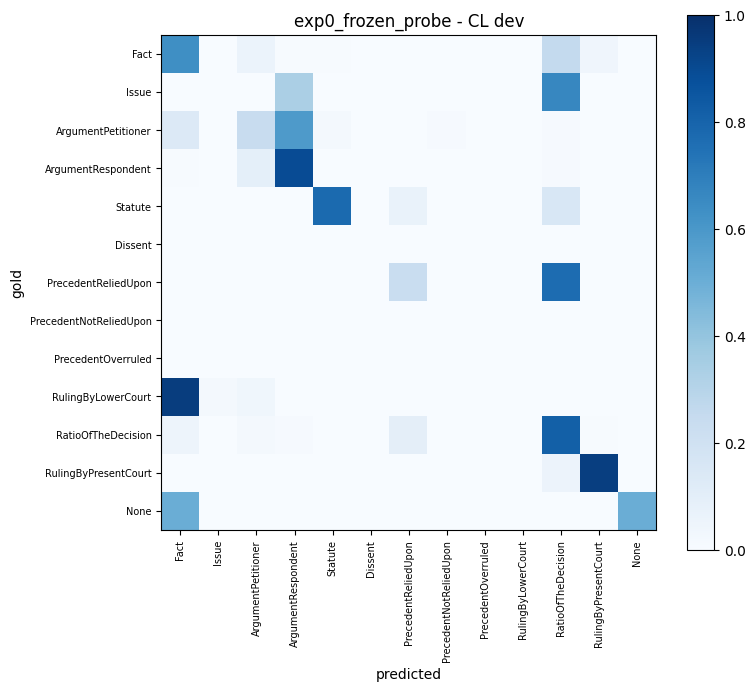

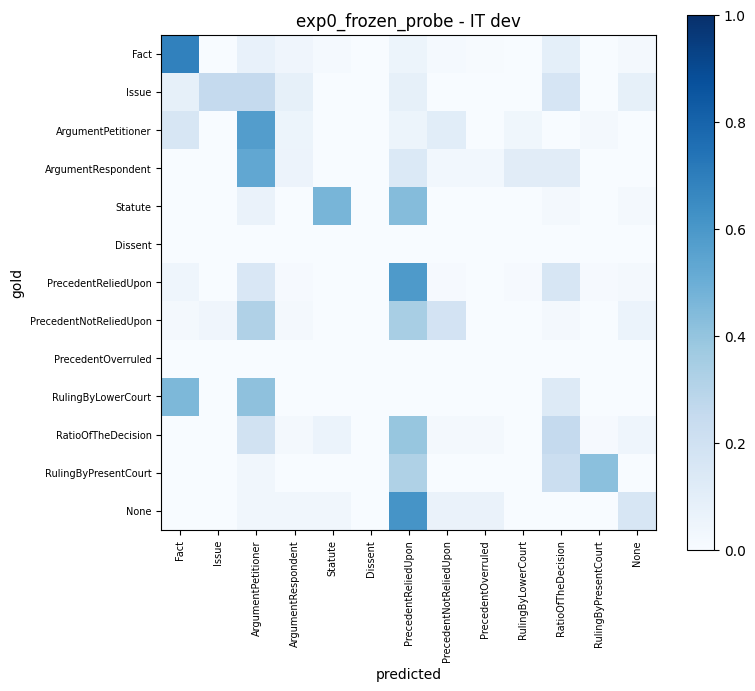

[exp0_frozen_probe] dev mean union-F1 = 0.3726 | zip: /content/drive/MyDrive/Phase3_Rhetorical_Role_prediction/experiments/exp0_frozen_probe/submission.zip


{'name': 'exp0_frozen_probe',
 'technique': 'frozen Phase-1 encoder + hierarchical head',
 'phase1_model': 'encdec',
 'trainable_params': 2112525,
 'total_params': 56648717,
 'train_seconds': 306.91520285606384,
 'notes': 'best_epoch=8; dev_infer_sec=1.4; refit=False; ',
 'submitted': False,
 'time': '2026-10-15 16:49',
 'CL_F1_all13': 0.3672,
 'CL_F1_union': 0.4339,
 'CL_F1_support': 0.4773,
 'IT_F1_all13': 0.2874,
 'IT_F1_union': 0.3114,
 'IT_F1_support': 0.3397,
 'mean_F1_union': 0.3726}

In [ ]:
# 0) diagnostic: frozen Phase-1 encoder, head only
run_rr("exp0_frozen_probe", "frozen Phase-1 encoder + hierarchical head", {"method": "frozen", "epochs": 25})

[exp1_full_ft] method=full trainable=56.65M / total=56.65M
{"epoch": 1, "train_loss": 2.5654, "sec": 57.4, "dev_mean_F1": 0.2405, "CL_F1": 0.2633, "IT_F1": 0.2178}
{"epoch": 2, "train_loss": 2.1235, "sec": 57.2, "dev_mean_F1": 0.3656, "CL_F1": 0.3872, "IT_F1": 0.3441}
{"epoch": 3, "train_loss": 1.8571, "sec": 57.3, "dev_mean_F1": 0.353, "CL_F1": 0.4247, "IT_F1": 0.2813}
{"epoch": 4, "train_loss": 1.6027, "sec": 56.9, "dev_mean_F1": 0.3324, "CL_F1": 0.3387, "IT_F1": 0.3261}
{"epoch": 5, "train_loss": 1.4424, "sec": 57.8, "dev_mean_F1": 0.3491, "CL_F1": 0.3417, "IT_F1": 0.3565}
{"epoch": 6, "train_loss": 1.3239, "sec": 57.3, "dev_mean_F1": 0.3823, "CL_F1": 0.357, "IT_F1": 0.4076}
{"epoch": 7, "train_loss": 1.1886, "sec": 57.7, "dev_mean_F1": 0.3544, "CL_F1": 0.3161, "IT_F1": 0.3928}
{"epoch": 8, "train_loss": 1.109, "sec": 57.4, "dev_mean_F1": 0.3689, "CL_F1": 0.3112, "IT_F1": 0.4267}
{"epoch": 9, "train_loss": 1.053, "sec": 57.3, "dev_mean_F1": 0.378, "CL_F1": 0.3446, "IT_F1": 0.4115}
{

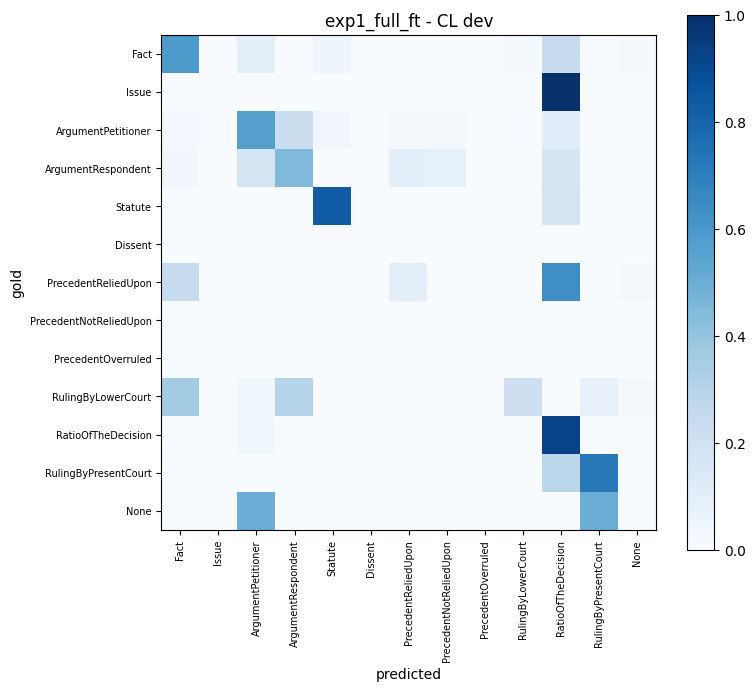

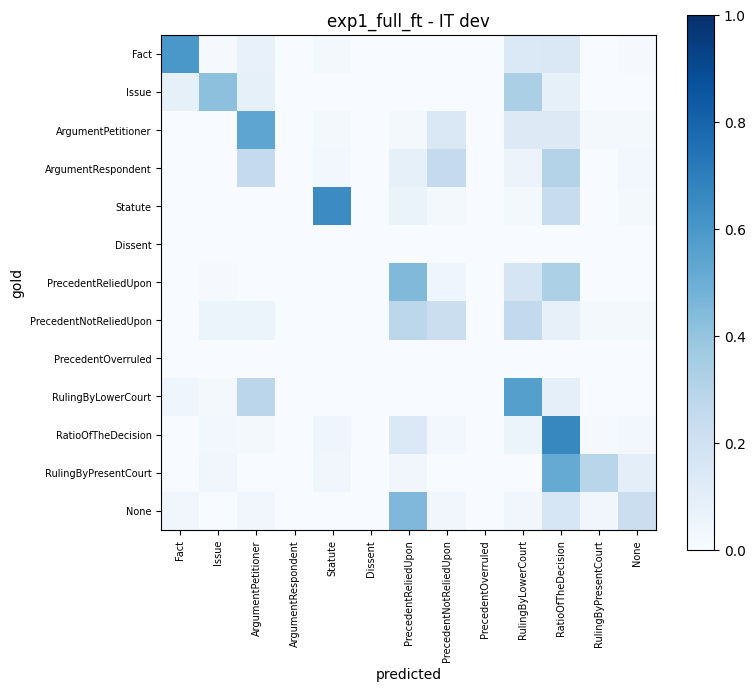

[exp1_full_ft] dev mean union-F1 = 0.3823 | zip: /content/drive/MyDrive/Phase3_Rhetorical_Role_prediction/experiments/exp1_full_ft/submission.zip


{'name': 'exp1_full_ft',
 'technique': 'full fine-tuning + hierarchical head',
 'phase1_model': 'encdec',
 'trainable_params': 56648717,
 'total_params': 56648717,
 'train_seconds': 587.1085016727448,
 'notes': 'best_epoch=6; dev_infer_sec=1.4; refit=False; ',
 'submitted': False,
 'time': '2026-10-15 16:59',
 'CL_F1_all13': 0.3295,
 'CL_F1_union': 0.357,
 'CL_F1_support': 0.4284,
 'IT_F1_all13': 0.3449,
 'IT_F1_union': 0.4076,
 'IT_F1_support': 0.4076,
 'mean_F1_union': 0.3823}

In [ ]:
# 1) full fine-tuning (kept in memory as KD teacher)
run_rr("exp1_full_ft", "full fine-tuning + hierarchical head", {"method": "full"}, keep=True)

[exp2_lora] method=lora trainable=2.96M / total=57.50M
{"epoch": 1, "train_loss": 2.5912, "sec": 70.0, "dev_mean_F1": 0.261, "CL_F1": 0.2575, "IT_F1": 0.2645}
{"epoch": 2, "train_loss": 2.1815, "sec": 69.9, "dev_mean_F1": 0.3511, "CL_F1": 0.3888, "IT_F1": 0.3134}
{"epoch": 3, "train_loss": 1.9356, "sec": 70.5, "dev_mean_F1": 0.3032, "CL_F1": 0.2857, "IT_F1": 0.3208}
{"epoch": 4, "train_loss": 1.7218, "sec": 70.0, "dev_mean_F1": 0.4036, "CL_F1": 0.4212, "IT_F1": 0.3861}
{"epoch": 5, "train_loss": 1.5721, "sec": 70.7, "dev_mean_F1": 0.3322, "CL_F1": 0.3708, "IT_F1": 0.2936}
{"epoch": 6, "train_loss": 1.4277, "sec": 69.7, "dev_mean_F1": 0.3955, "CL_F1": 0.3586, "IT_F1": 0.4324}
{"epoch": 7, "train_loss": 1.2753, "sec": 70.6, "dev_mean_F1": 0.3482, "CL_F1": 0.3455, "IT_F1": 0.3508}
{"epoch": 8, "train_loss": 1.1734, "sec": 70.5, "dev_mean_F1": 0.4161, "CL_F1": 0.3903, "IT_F1": 0.4419}
{"epoch": 9, "train_loss": 1.0944, "sec": 70.5, "dev_mean_F1": 0.3864, "CL_F1": 0.3218, "IT_F1": 0.4509}
{

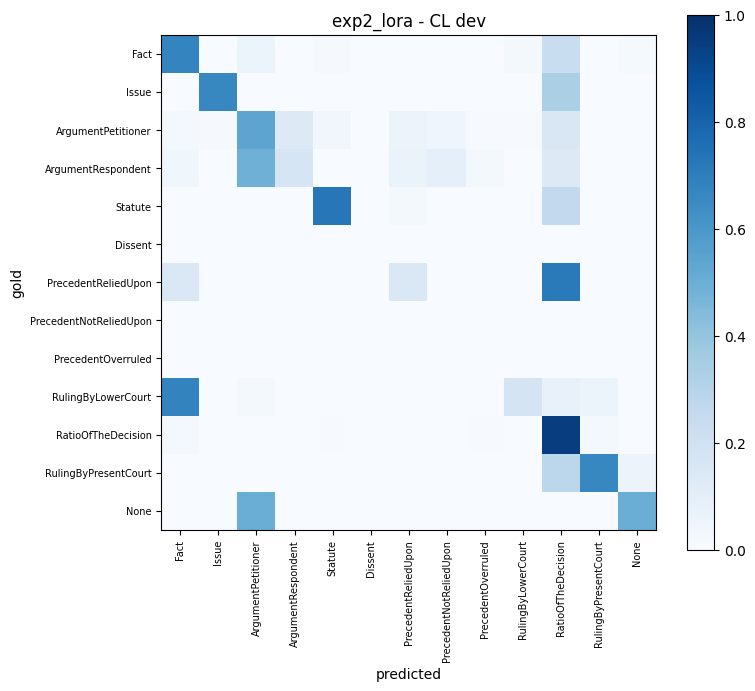

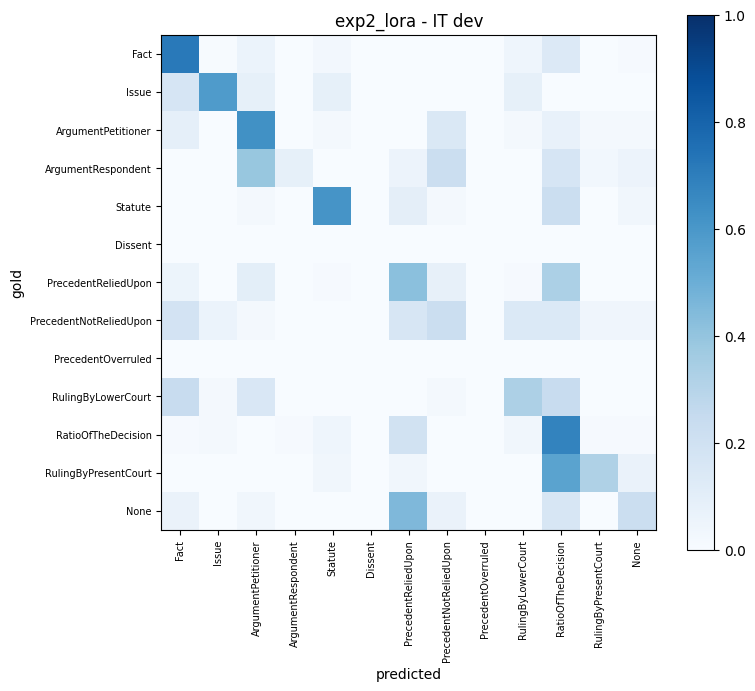

[exp2_lora] dev mean union-F1 = 0.4161 | zip: /content/drive/MyDrive/Phase3_Rhetorical_Role_prediction/experiments/exp2_lora/submission.zip


{'name': 'exp2_lora',
 'technique': 'LoRA r=8 on all attention+FFN linears',
 'phase1_model': 'encdec',
 'trainable_params': 2960397,
 'total_params': 57496589,
 'train_seconds': 864.3577373027802,
 'notes': 'best_epoch=8; dev_infer_sec=1.9; refit=False; ',
 'submitted': False,
 'time': '2026-10-15 17:13',
 'CL_F1_all13': 0.3602,
 'CL_F1_union': 0.3903,
 'CL_F1_support': 0.4683,
 'IT_F1_all13': 0.3739,
 'IT_F1_union': 0.4419,
 'IT_F1_support': 0.4419,
 'mean_F1_union': 0.4161}

In [ ]:
# 2) LoRA
run_rr("exp2_lora", "LoRA r=8 on all attention+FFN linears", {"method": "lora"})

[exp3_lorma] method=lorma trainable=3.07M / total=57.61M
{"epoch": 1, "train_loss": 2.594, "sec": 64.6, "dev_mean_F1": 0.28, "CL_F1": 0.2833, "IT_F1": 0.2767}
{"epoch": 2, "train_loss": 2.2083, "sec": 64.2, "dev_mean_F1": 0.314, "CL_F1": 0.3322, "IT_F1": 0.2957}
{"epoch": 3, "train_loss": 1.9634, "sec": 64.5, "dev_mean_F1": 0.3459, "CL_F1": 0.3848, "IT_F1": 0.3071}
{"epoch": 4, "train_loss": 1.7633, "sec": 64.3, "dev_mean_F1": 0.3499, "CL_F1": 0.3758, "IT_F1": 0.3239}
{"epoch": 5, "train_loss": 1.641, "sec": 65.1, "dev_mean_F1": 0.3417, "CL_F1": 0.3856, "IT_F1": 0.2977}
{"epoch": 6, "train_loss": 1.4992, "sec": 64.3, "dev_mean_F1": 0.3903, "CL_F1": 0.4158, "IT_F1": 0.3648}
{"epoch": 7, "train_loss": 1.3263, "sec": 65.8, "dev_mean_F1": 0.3528, "CL_F1": 0.3391, "IT_F1": 0.3665}
{"epoch": 8, "train_loss": 1.2268, "sec": 65.5, "dev_mean_F1": 0.3874, "CL_F1": 0.3668, "IT_F1": 0.408}
{"epoch": 9, "train_loss": 1.1381, "sec": 64.9, "dev_mean_F1": 0.3657, "CL_F1": 0.3125, "IT_F1": 0.4189}
{"ep

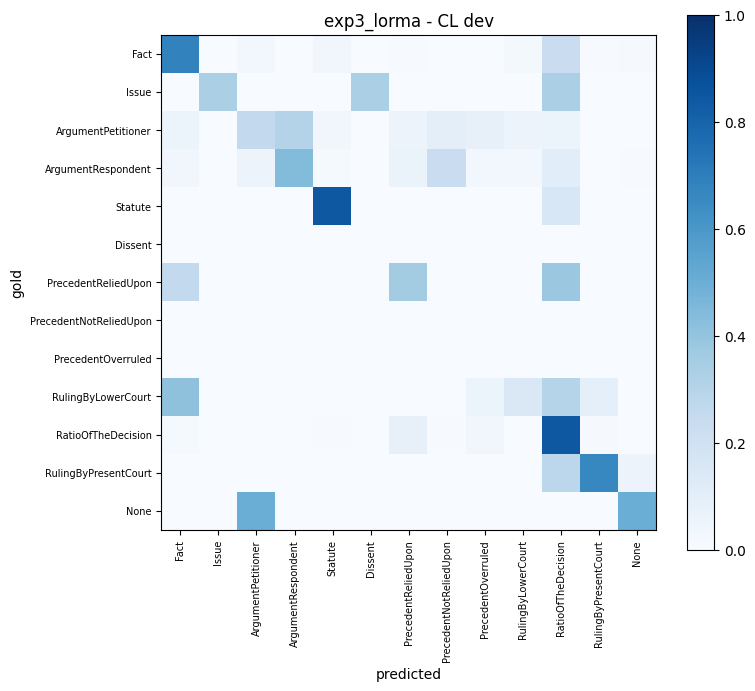

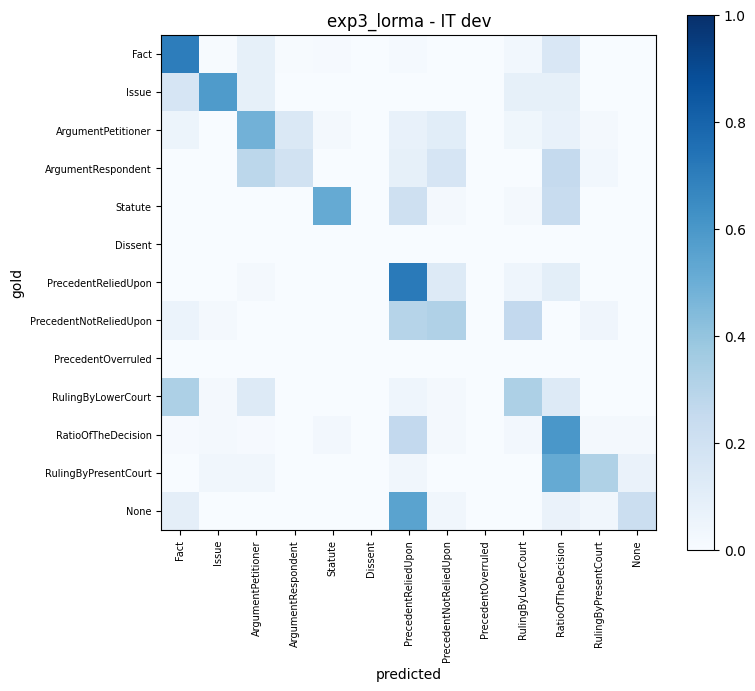

[exp3_lorma] dev mean union-F1 = 0.4242 | zip: /content/drive/MyDrive/Phase3_Rhetorical_Role_prediction/experiments/exp3_lorma/submission.zip


{'name': 'exp3_lorma',
 'technique': 'LoRMA+ (multiplicative low-rank, additive inflation)',
 'phase1_model': 'encdec',
 'trainable_params': 3070989,
 'total_params': 57607181,
 'train_seconds': 1002.5033860206604,
 'notes': 'best_epoch=14; dev_infer_sec=1.8; refit=False; ',
 'submitted': False,
 'time': '2026-10-15 17:30',
 'CL_F1_all13': 0.3794,
 'CL_F1_union': 0.3794,
 'CL_F1_support': 0.4932,
 'IT_F1_all13': 0.3968,
 'IT_F1_union': 0.4689,
 'IT_F1_support': 0.4689,
 'mean_F1_union': 0.4242}

In [ ]:
# 3) LoRMA+ (compulsory)
run_rr("exp3_lorma", "LoRMA+ (multiplicative low-rank, additive inflation)", {"method": "lorma"})

[exp4_rslora] method=rslora trainable=3.81M / total=58.34M
{"epoch": 1, "train_loss": 2.5467, "sec": 71.1, "dev_mean_F1": 0.2666, "CL_F1": 0.2852, "IT_F1": 0.2481}
{"epoch": 2, "train_loss": 2.1996, "sec": 70.5, "dev_mean_F1": 0.3222, "CL_F1": 0.3145, "IT_F1": 0.3299}
{"epoch": 3, "train_loss": 1.9576, "sec": 71.4, "dev_mean_F1": 0.2844, "CL_F1": 0.2484, "IT_F1": 0.3203}
{"epoch": 4, "train_loss": 1.7865, "sec": 70.5, "dev_mean_F1": 0.336, "CL_F1": 0.338, "IT_F1": 0.3341}
{"epoch": 5, "train_loss": 1.6432, "sec": 71.3, "dev_mean_F1": 0.3075, "CL_F1": 0.3273, "IT_F1": 0.2877}
{"epoch": 6, "train_loss": 1.501, "sec": 70.6, "dev_mean_F1": 0.413, "CL_F1": 0.4343, "IT_F1": 0.3918}
{"epoch": 7, "train_loss": 1.3286, "sec": 71.7, "dev_mean_F1": 0.3792, "CL_F1": 0.2954, "IT_F1": 0.463}
{"epoch": 8, "train_loss": 1.2347, "sec": 71.9, "dev_mean_F1": 0.403, "CL_F1": 0.3941, "IT_F1": 0.4119}
{"epoch": 9, "train_loss": 1.1191, "sec": 71.5, "dev_mean_F1": 0.3973, "CL_F1": 0.4012, "IT_F1": 0.3935}
{"

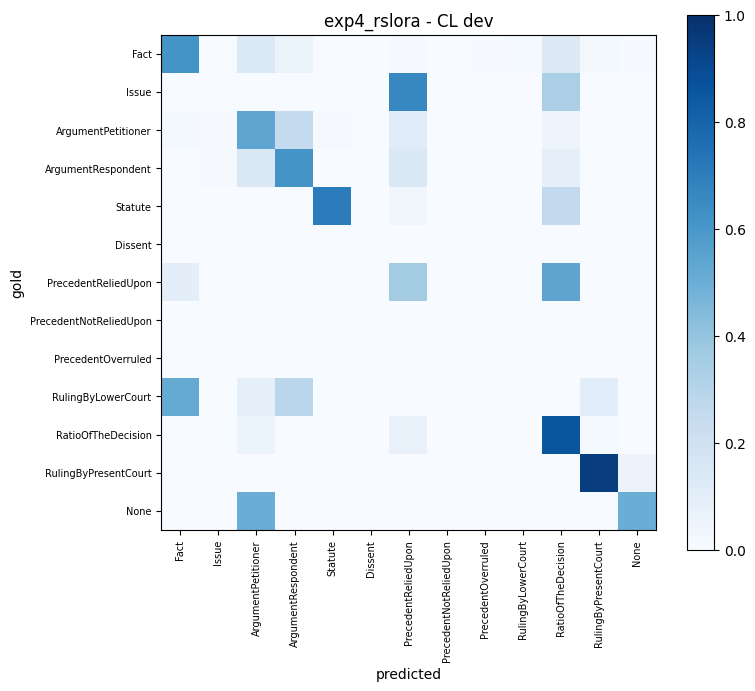

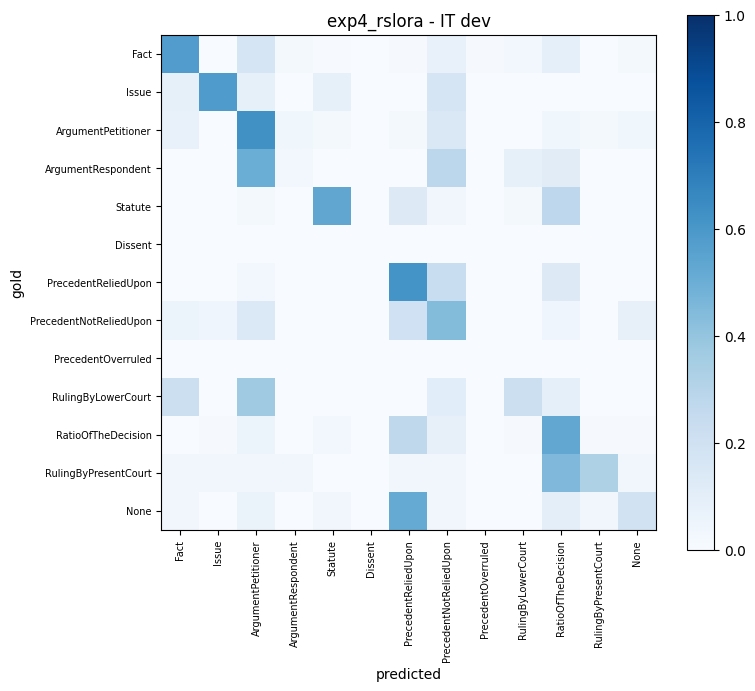

[exp4_rslora] dev mean union-F1 = 0.4130 | zip: /content/drive/MyDrive/Phase3_Rhetorical_Role_prediction/experiments/exp4_rslora/submission.zip


{'name': 'exp4_rslora',
 'technique': 'rsLoRA (alpha/sqrt(r) scaling)',
 'phase1_model': 'encdec',
 'trainable_params': 3808269,
 'total_params': 58344461,
 'train_seconds': 730.1026663780212,
 'notes': 'best_epoch=6; dev_infer_sec=1.9; refit=False; ',
 'submitted': False,
 'time': '2026-10-15 17:42',
 'CL_F1_all13': 0.3675,
 'CL_F1_union': 0.4343,
 'CL_F1_support': 0.4777,
 'IT_F1_all13': 0.3616,
 'IT_F1_union': 0.3918,
 'IT_F1_support': 0.4274,
 'mean_F1_union': 0.413}

In [ ]:
# 4) rank-stabilised LoRA  (or swap for "ia3" - see next cell)
run_rr("exp4_rslora", "rsLoRA (alpha/sqrt(r) scaling)", {"method": "rslora", "r": 16})

[exp5_ia3] method=ia3 trainable=2.14M / total=56.68M
{"epoch": 1, "train_loss": 2.6125, "sec": 60.2, "dev_mean_F1": 0.2608, "CL_F1": 0.2795, "IT_F1": 0.2422}
{"epoch": 2, "train_loss": 2.2962, "sec": 59.9, "dev_mean_F1": 0.2894, "CL_F1": 0.3165, "IT_F1": 0.2622}
{"epoch": 3, "train_loss": 2.0835, "sec": 60.1, "dev_mean_F1": 0.2652, "CL_F1": 0.2818, "IT_F1": 0.2486}
{"epoch": 4, "train_loss": 1.9251, "sec": 59.7, "dev_mean_F1": 0.3278, "CL_F1": 0.3176, "IT_F1": 0.3381}
{"epoch": 5, "train_loss": 1.8042, "sec": 60.2, "dev_mean_F1": 0.3445, "CL_F1": 0.4014, "IT_F1": 0.2877}
{"epoch": 6, "train_loss": 1.7135, "sec": 59.8, "dev_mean_F1": 0.3316, "CL_F1": 0.3256, "IT_F1": 0.3375}
{"epoch": 7, "train_loss": 1.6251, "sec": 60.2, "dev_mean_F1": 0.3172, "CL_F1": 0.2961, "IT_F1": 0.3383}
{"epoch": 8, "train_loss": 1.5176, "sec": 60.2, "dev_mean_F1": 0.3561, "CL_F1": 0.3976, "IT_F1": 0.3146}
{"epoch": 9, "train_loss": 1.4181, "sec": 60.1, "dev_mean_F1": 0.3551, "CL_F1": 0.3341, "IT_F1": 0.3761}
{"

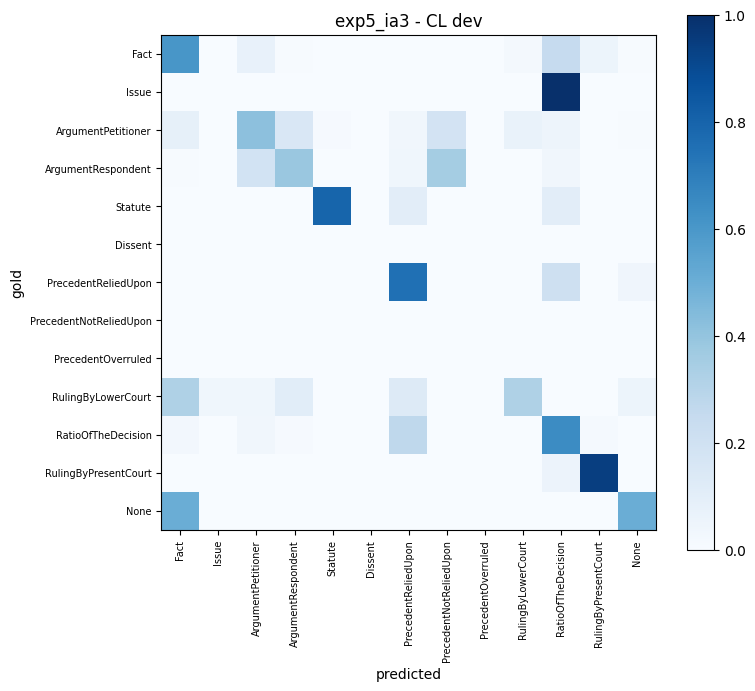

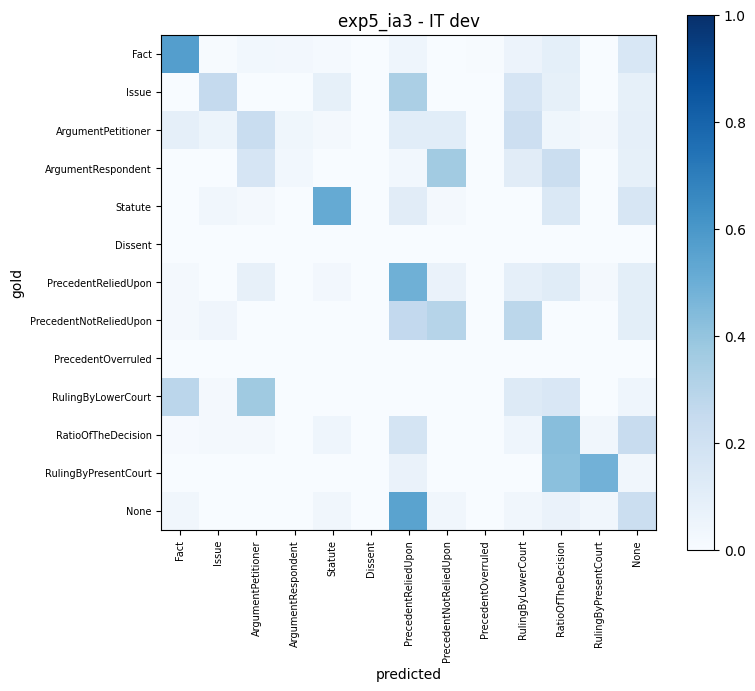

[exp5_ia3] dev mean union-F1 = 0.3755 | zip: /content/drive/MyDrive/Phase3_Rhetorical_Role_prediction/experiments/exp5_ia3/submission.zip


{'name': 'exp5_ia3',
 'technique': 'IA3 (learned scaling of K, V, FFN activations)',
 'phase1_model': 'encdec',
 'trainable_params': 2140173,
 'total_params': 56676365,
 'train_seconds': 862.2700741291046,
 'notes': 'best_epoch=10; dev_infer_sec=1.6; refit=False; ',
 'submitted': False,
 'time': '2026-10-15 17:57',
 'CL_F1_all13': 0.3723,
 'CL_F1_union': 0.44,
 'CL_F1_support': 0.484,
 'IT_F1_all13': 0.2871,
 'IT_F1_union': 0.311,
 'IT_F1_support': 0.3393,
 'mean_F1_union': 0.3755}

In [ ]:
# 5) IA3 -- different mechanism (learned activation scaling, ~tens of thousands of params)
run_rr("exp5_ia3", "IA3 (learned scaling of K, V, FFN activations)", {"method": "ia3"})

[exp5b_prompt] method=prompt trainable=2.12M / total=56.66M
{"epoch": 1, "train_loss": 2.6411, "sec": 57.9, "dev_mean_F1": 0.2474, "CL_F1": 0.2751, "IT_F1": 0.2198}
{"epoch": 2, "train_loss": 2.2838, "sec": 57.8, "dev_mean_F1": 0.3076, "CL_F1": 0.3524, "IT_F1": 0.2628}
{"epoch": 3, "train_loss": 2.0916, "sec": 57.4, "dev_mean_F1": 0.2736, "CL_F1": 0.2934, "IT_F1": 0.2538}
{"epoch": 4, "train_loss": 1.9506, "sec": 57.2, "dev_mean_F1": 0.306, "CL_F1": 0.3238, "IT_F1": 0.2881}
{"epoch": 5, "train_loss": 1.8346, "sec": 57.8, "dev_mean_F1": 0.2963, "CL_F1": 0.3587, "IT_F1": 0.234}
{"epoch": 6, "train_loss": 1.7557, "sec": 57.4, "dev_mean_F1": 0.3352, "CL_F1": 0.3587, "IT_F1": 0.3117}
{"epoch": 7, "train_loss": 1.64, "sec": 57.8, "dev_mean_F1": 0.3539, "CL_F1": 0.3582, "IT_F1": 0.3495}
{"epoch": 8, "train_loss": 1.5398, "sec": 57.8, "dev_mean_F1": 0.3467, "CL_F1": 0.3699, "IT_F1": 0.3234}
{"epoch": 9, "train_loss": 1.4548, "sec": 57.3, "dev_mean_F1": 0.3295, "CL_F1": 0.3059, "IT_F1": 0.3531}

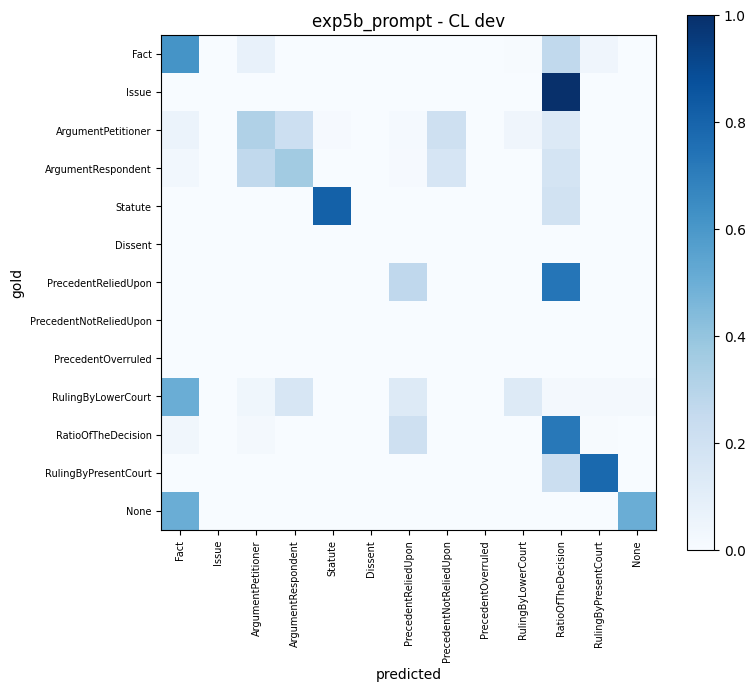

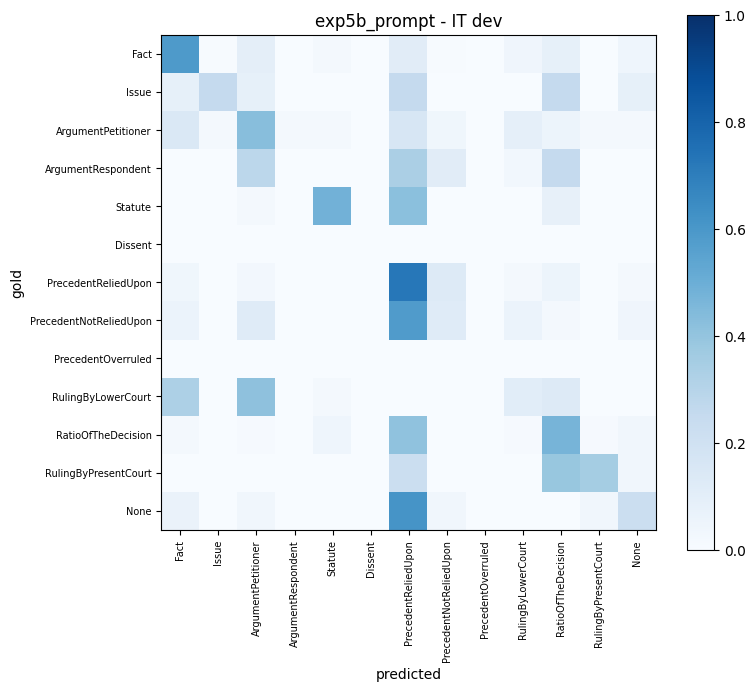

[exp5b_prompt] dev mean union-F1 = 0.3796 | zip: /content/drive/MyDrive/Phase3_Rhetorical_Role_prediction/experiments/exp5b_prompt/submission.zip
[exp5c_partial] method=partial trainable=14.70M / total=56.65M
{"epoch": 1, "train_loss": 2.6101, "sec": 34.2, "dev_mean_F1": 0.2584, "CL_F1": 0.2759, "IT_F1": 0.2409}
{"epoch": 2, "train_loss": 2.2669, "sec": 34.1, "dev_mean_F1": 0.2912, "CL_F1": 0.3221, "IT_F1": 0.2604}
{"epoch": 3, "train_loss": 2.0354, "sec": 34.2, "dev_mean_F1": 0.2505, "CL_F1": 0.228, "IT_F1": 0.2731}
{"epoch": 4, "train_loss": 1.8741, "sec": 34.0, "dev_mean_F1": 0.3063, "CL_F1": 0.3138, "IT_F1": 0.2987}
{"epoch": 5, "train_loss": 1.7163, "sec": 34.4, "dev_mean_F1": 0.3178, "CL_F1": 0.3423, "IT_F1": 0.2933}
{"epoch": 6, "train_loss": 1.6274, "sec": 34.1, "dev_mean_F1": 0.3704, "CL_F1": 0.4038, "IT_F1": 0.337}
{"epoch": 7, "train_loss": 1.5096, "sec": 34.3, "dev_mean_F1": 0.3557, "CL_F1": 0.3388, "IT_F1": 0.3726}
{"epoch": 8, "train_loss": 1.3952, "sec": 34.2, "dev_mean_

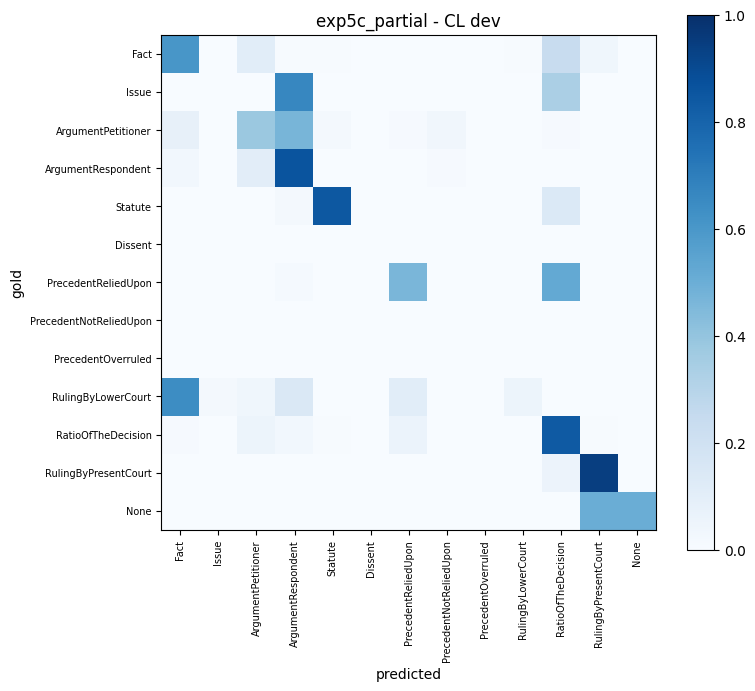

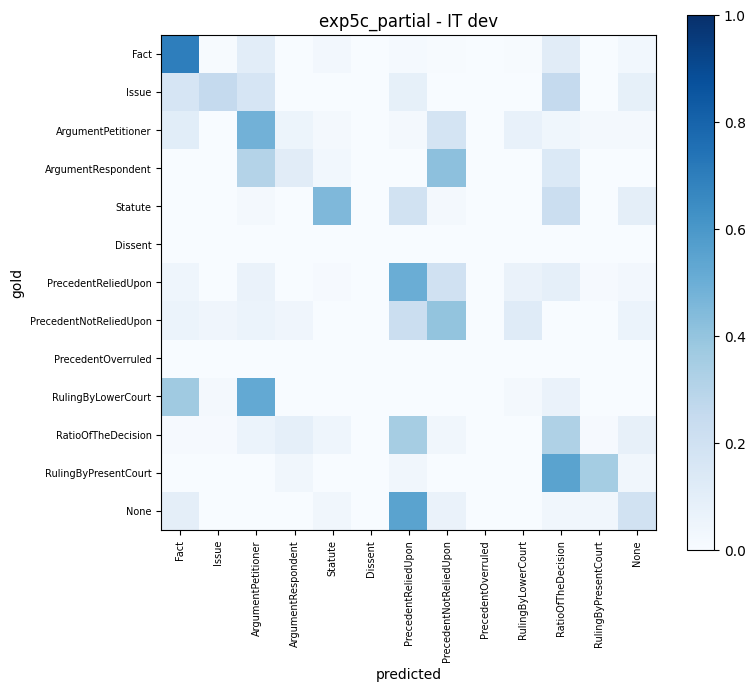

[exp5c_partial] dev mean union-F1 = 0.4188 | zip: /content/drive/MyDrive/Phase3_Rhetorical_Role_prediction/experiments/exp5c_partial/submission.zip


{'name': 'exp5c_partial',
 'technique': 'partial fine-tuning (top 3 encoder layers)',
 'phase1_model': 'encdec',
 'trainable_params': 14699021,
 'total_params': 56648717,
 'train_seconds': 425.8875584602356,
 'notes': 'best_epoch=8; dev_infer_sec=1.4; refit=False; ',
 'submitted': False,
 'time': '2026-10-15 18:19',
 'CL_F1_all13': 0.4138,
 'CL_F1_union': 0.4891,
 'CL_F1_support': 0.538,
 'IT_F1_all13': 0.295,
 'IT_F1_union': 0.3486,
 'IT_F1_support': 0.3486,
 'mean_F1_union': 0.4188}

In [ ]:
# 5b) optional extras: prompt tuning and partial fine-tuning (top 3 layers)
run_rr("exp5b_prompt", "prompt tuning (16 soft tokens)", {"method": "prompt"})
run_rr("exp5c_partial", "partial fine-tuning (top 3 encoder layers)", {"method": "partial", "unfreeze_top": 3})

[exp6_kd_student] method=full trainable=35.67M / total=35.67M
{"epoch": 1, "train_loss": 2.1128, "sec": 47.9, "dev_mean_F1": 0.2663, "CL_F1": 0.2837, "IT_F1": 0.2489}
{"epoch": 2, "train_loss": 1.5989, "sec": 47.8, "dev_mean_F1": 0.3384, "CL_F1": 0.3837, "IT_F1": 0.293}
{"epoch": 3, "train_loss": 1.262, "sec": 47.7, "dev_mean_F1": 0.3376, "CL_F1": 0.374, "IT_F1": 0.3012}
{"epoch": 4, "train_loss": 1.0134, "sec": 47.5, "dev_mean_F1": 0.3655, "CL_F1": 0.4034, "IT_F1": 0.3277}
{"epoch": 5, "train_loss": 0.8783, "sec": 48.2, "dev_mean_F1": 0.3276, "CL_F1": 0.2867, "IT_F1": 0.3686}
{"epoch": 6, "train_loss": 0.7915, "sec": 47.5, "dev_mean_F1": 0.3586, "CL_F1": 0.3349, "IT_F1": 0.3823}
{"epoch": 7, "train_loss": 0.7071, "sec": 47.7, "dev_mean_F1": 0.3449, "CL_F1": 0.3232, "IT_F1": 0.3665}
{"epoch": 8, "train_loss": 0.6718, "sec": 47.7, "dev_mean_F1": 0.3827, "CL_F1": 0.337, "IT_F1": 0.4284}
{"epoch": 9, "train_loss": 0.6356, "sec": 47.6, "dev_mean_F1": 0.3775, "CL_F1": 0.3463, "IT_F1": 0.408

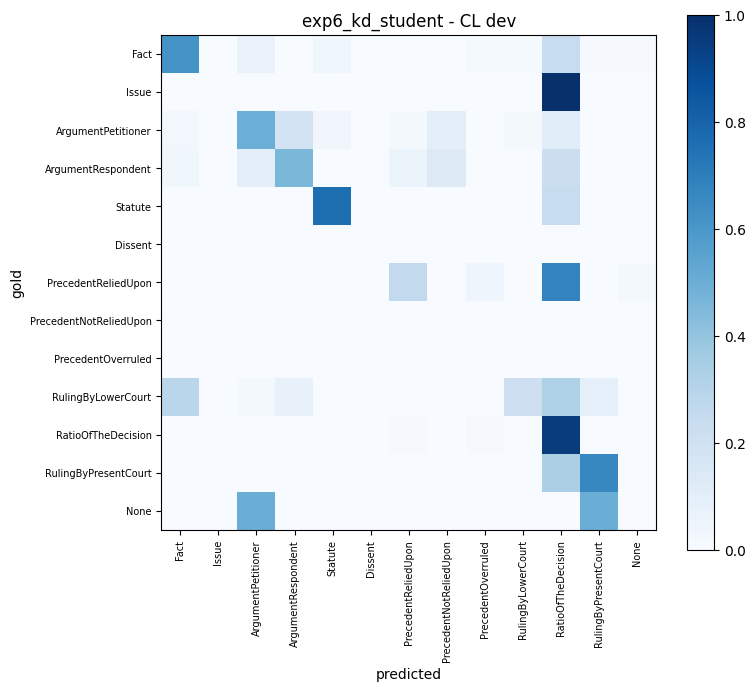

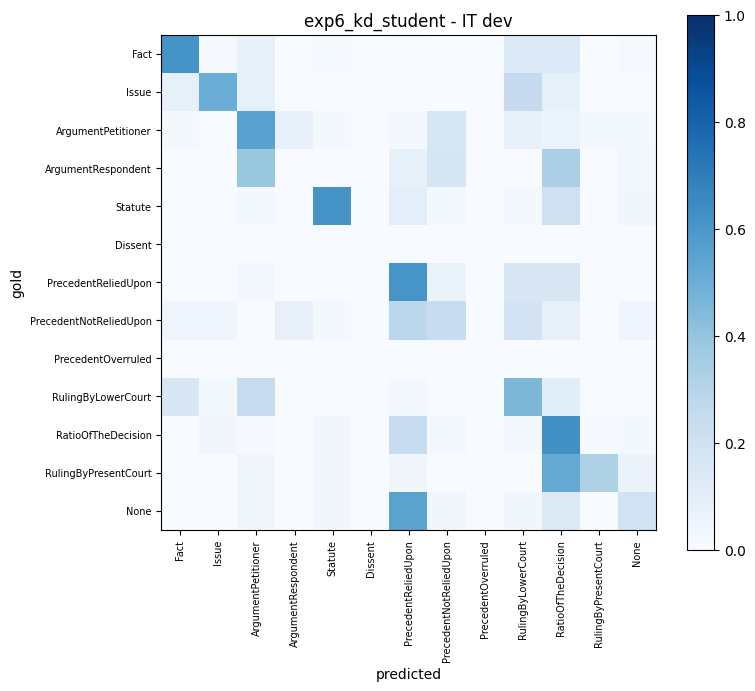

[exp6_kd_student] dev mean union-F1 = 0.3976 | zip: /content/drive/MyDrive/Phase3_Rhetorical_Role_prediction/experiments/exp6_kd_student/submission.zip
[exp6b_student_no_kd] method=full trainable=35.67M / total=35.67M
{"epoch": 1, "train_loss": 2.5796, "sec": 29.2, "dev_mean_F1": 0.2583, "CL_F1": 0.2808, "IT_F1": 0.2358}
{"epoch": 2, "train_loss": 2.1607, "sec": 29.0, "dev_mean_F1": 0.3219, "CL_F1": 0.3351, "IT_F1": 0.3088}
{"epoch": 3, "train_loss": 1.8616, "sec": 29.0, "dev_mean_F1": 0.3425, "CL_F1": 0.4027, "IT_F1": 0.2822}
{"epoch": 4, "train_loss": 1.6063, "sec": 28.9, "dev_mean_F1": 0.3787, "CL_F1": 0.4107, "IT_F1": 0.3467}
{"epoch": 5, "train_loss": 1.4433, "sec": 29.2, "dev_mean_F1": 0.3169, "CL_F1": 0.2701, "IT_F1": 0.3637}
{"epoch": 6, "train_loss": 1.3458, "sec": 29.0, "dev_mean_F1": 0.3899, "CL_F1": 0.3548, "IT_F1": 0.425}
{"epoch": 7, "train_loss": 1.2188, "sec": 29.2, "dev_mean_F1": 0.4048, "CL_F1": 0.4137, "IT_F1": 0.3959}
{"epoch": 8, "train_loss": 1.138, "sec": 29.0, "

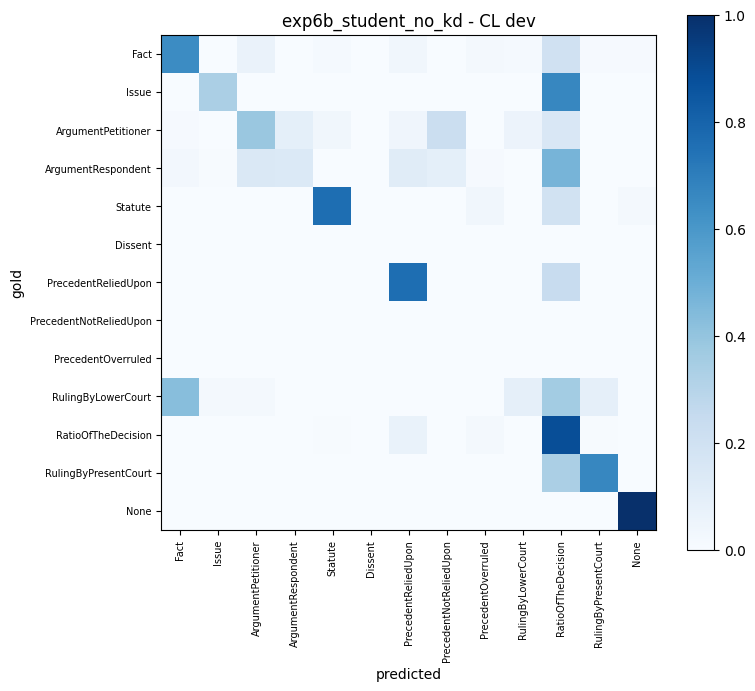

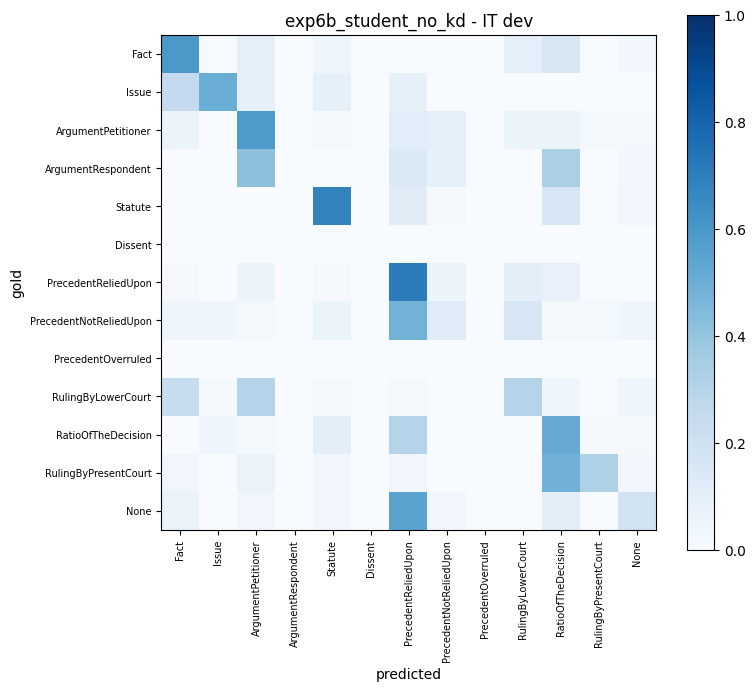

[exp6b_student_no_kd] dev mean union-F1 = 0.4048 | zip: /content/drive/MyDrive/Phase3_Rhetorical_Role_prediction/experiments/exp6b_student_no_kd/submission.zip


{'name': 'exp6b_student_no_kd',
 'technique': '4-layer student, hard labels only (KD ablation)',
 'phase1_model': 'encdec (bottom 4 layers)',
 'trainable_params': 35672077,
 'total_params': 35672077,
 'train_seconds': 326.13788652420044,
 'notes': 'best_epoch=7; dev_infer_sec=0.7; refit=False; ',
 'submitted': False,
 'time': '2026-10-15 18:37',
 'CL_F1_all13': 0.3819,
 'CL_F1_union': 0.4137,
 'CL_F1_support': 0.4965,
 'IT_F1_all13': 0.335,
 'IT_F1_union': 0.3959,
 'IT_F1_support': 0.3959,
 'mean_F1_union': 0.4048}

In [ ]:
# 6) knowledge distillation: teacher = exp1 (9-layer encoder, full FT) -> student = bottom-4 Phase-1 encoder layers
teacher = MODELS["exp1_full_ft"]
run_rr("exp6_kd_student", "KD: 9-layer teacher -> 4-layer student (CE + KL on logits)",
       {"method": "full", "kd_alpha": 0.5, "kd_T": 2.0}, n_layers=4, teacher=teacher,
       notes="teacher=exp1_full_ft")
# For a fair KD comparison also run the same 4-layer student WITHOUT the teacher:
run_rr("exp6b_student_no_kd", "4-layer student, hard labels only (KD ablation)", {"method": "full"}, n_layers=4)

## 10. Summary table and training curves (ancillary; interpret the results yourself)

                  name                                          technique  \
0    exp0_frozen_probe         frozen Phase-1 encoder + hierarchical head   
1         exp1_full_ft               full fine-tuning + hierarchical head   
2            exp2_lora              LoRA r=8 on all attention+FFN linears   
3           exp3_lorma  LoRMA+ (multiplicative low-rank, additive infl...   
4          exp4_rslora                     rsLoRA (alpha/sqrt(r) scaling)   
5             exp5_ia3     IA3 (learned scaling of K, V, FFN activations)   
6         exp5b_prompt                     prompt tuning (16 soft tokens)   
7        exp5c_partial         partial fine-tuning (top 3 encoder layers)   
8      exp6_kd_student  KD: 9-layer teacher -> 4-layer student (CE + K...   
9  exp6b_student_no_kd    4-layer student, hard labels only (KD ablation)   

   trainable_params  total_params  CL_F1_union  IT_F1_union  mean_F1_union  \
0           2112525      56648717       0.4339       0.3114         0.3726

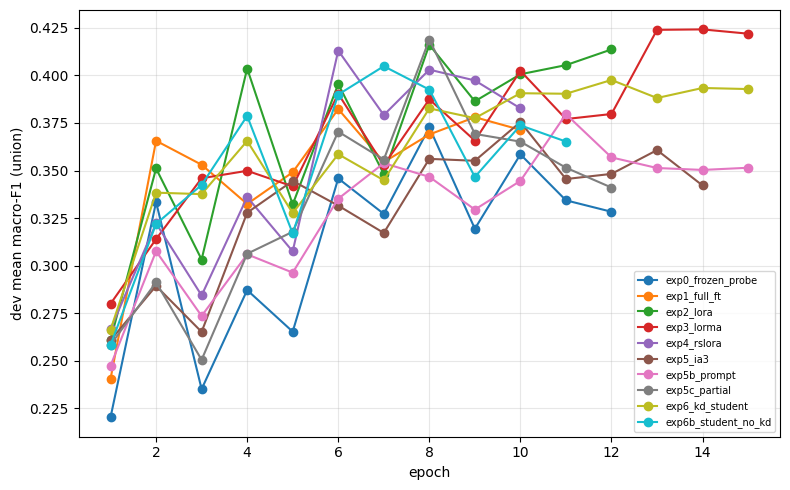

In [ ]:
reg = pd.DataFrame(registry)
cols = ["name", "technique", "trainable_params", "total_params", "CL_F1_union", "IT_F1_union", "mean_F1_union", "train_seconds", "notes"]
display(reg[[c for c in cols if c in reg.columns]]) if "display" in dir() else print(reg[cols])

fig, ax = plt.subplots(figsize=(8, 5))
for name, r in RUNS.items():
    h = pd.DataFrame(r["hist"])
    if "dev_mean_F1" in h: ax.plot(h["epoch"], h["dev_mean_F1"], marker="o", label=name)
ax.set_xlabel("epoch"); ax.set_ylabel("dev mean macro-F1 (union)"); ax.legend(fontsize=7); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, "dev_curves.png"), dpi=150); plt.show()

## Notes
* Pick your headline metric variant to match the official evaluator (`all13` / `union` / `support`) and set `eval_dev` accordingly.
* The dev sets are tiny (5 docs/domain): differences of a point or two between methods are noise. Use `make_doc_folds` (scaffold) for CV before drawing conclusions.
* Pass `refit=True` for your final submissions to train on train+dev.
* Cite: Hu et al. 2021 (LoRA), Kalajdzievski 2023 (rsLoRA), Bihany et al. 2025 (LoRMA), Liu et al. 2022 (IA³), Lester et al. 2021 (prompt tuning), Hinton et al. 2015 (distillation).

In [ ]:
# 3) LoRMA+ (compulsory)
run_rr("exp3_lorma", "LoRMA+ (multiplicative low-rank, additive inflation)", {"method": "lorma"}, )